# IE7615 — Discriminative Project, Milestone 2
## Multi-object detection on grid images: fine-tuning YOLOE-26s on auto-labelled object boxes

**Models: YOLOE-26 as the pretrained model.** YOLOE-26 is Ultralytics' open-vocabulary detector built on YOLO26 and pre-trained on large detection and grounding datasets (Objects365, GQA, Flickr30k). It already links image regions to *words*, so it starts out knowing what "tennis ball" or "pencil case" looks like. We fine-tune its **small** size (YOLOE-26s) as a **detector** on our grids with Ultralytics' prompt-embedding fine-tuning recipe (`YOLOEPETrainer`): the 72 object names initialise the classification head, then the whole network is trained on our labels. The confidence threshold is chosen on validation only; the test set is used only for reporting.

## 1. Setup

In [4]:
# Install / upgrade the packages (Colab). YOLOE-26 needs ultralytics 8.4.0 or newer.
import sys, subprocess, importlib.util
def has(mod):
    try:
        return importlib.util.find_spec(mod) is not None
    except (ImportError, ValueError):
        return False
need = [] if has("openpyxl") else ["openpyxl"]
if has("ultralytics"):
    import ultralytics
    if tuple(int(x) for x in ultralytics.__version__.split(".")[:2]) < (8, 4):
        need.append("ultralytics>=8.4.0")
else:
    need.append("ultralytics>=8.4.0")
if need:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U"] + need, check=True)
    print("Installed:", need, "-> now do Runtime > Restart session once, then continue with the next cell")
else:
    import ultralytics
    print("Packages ready | ultralytics", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Packages ready | ultralytics 8.4.175


In [5]:
import os, re, io, json, math, time, random, shutil, hashlib, pickle, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter, ImageEnhance, ImageDraw
from sklearn.model_selection import train_test_split

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---------------- paths (Google Colab) ----------------
assert IN_COLAB, "This notebook is set up for Google Colab"
SAVE_DIR    = Path("/content/drive/MyDrive/IE7615_M2_final")   # YOUR Drive: labels, grids zip, models, results (kept)
EXTRACT_DIR = Path("/content/data")                             # local copy of the dataset (fast, wiped on disconnect)
WORK_DIR    = Path("/content/m2_work")                          # local temporary files (fast, wiped on disconnect)
ZIP_PATH    = "/content/drive/MyDrive/IE7615DeepLearning.zip"   # optional: the dataset as a zip in My Drive
CLEAN_DIR   = WORK_DIR / "clean_images"      # cleaned working copy of the single-object photos
YOLO_DIR    = WORK_DIR / "yolo_dataset"      # generated grid dataset (images/ + labels/)
RUNS_DIR    = SAVE_DIR / "runs"              # YOLO training runs (on Drive so a disconnect can resume)
EVAL_DIR    = SAVE_DIR / "eval"
FIG_DIR     = SAVE_DIR / "figures"

# ---------------- data-fix settings ----------------
SEED     = 42
IMG_SIZE = 224                                           # every photo is used at 224 x 224 (non-224 files are resized)
BG_REGEX = re.compile(r"_bg_|bg\d+", re.IGNORECASE)      # background-only shots, e.g. OBJ012_bg_03.jpg, OBJ013_BG001.jpg
OBJ004_BG_FILES = ["OBJ004_007.jpg", "OBJ004_014.jpg", "OBJ004_023.jpg",
                   "OBJ004_030.jpg", "OBJ004_073.jpg"]   # verified by eye: no toy car in these photos
EXCLUDE_CLASSES = {"OBJ054"}                             # instructor: OBJ054 is not a photo of the object
EXCLUDE_BG      = {"OBJ035_bg_002.jpg",                  # acoustic guitar that may be OBJ022's guitar
                   "OBJ049_bg_001.jpg"}                  # plush toys, one may be OBJ021's white plush
CLASS_SUBSET    = None                                   # None = all remaining IDs; or a list, e.g. the SECTION-01 IDs

# ---------------- auto-labelling (bounding boxes) ----------------
LABELERS        = {"world": "yolov8x-worldv2.pt",       # YOLO-World (open-vocabulary, text prompt)
                   "yoloe": "yoloe-26l-seg.pt"}          # YOLOE-26 large (open-vocabulary, text prompt) -> second opinion
LABEL_IMGSZ     = 640                                    # photos are enlarged for labelling so small objects are found
LABEL_MIN_CONF  = 0.05                                   # weakest detection a labeller may return
AGREE_IOU       = 0.5                                    # both labellers must agree this well for a box to be kept
MIN_BOX_FRAC    = 0.01                                   # agreed box < 1 % of the photo (~22 x 22 px) = object too small / far
MIN_PHOTOS_PER_CLASS = 20                                # if a class keeps fewer, confident single-labeller boxes are added
SINGLE_MIN_CONF = 0.60                                   # ... but only when that labeller is at least this confident
MANUAL_DROP     = set()                                  # file names you reject after looking at the check figures
OBJECT_NAMES_CSV = SAVE_DIR / "object_names.csv"         # optional: columns object_id,name (overrides everything below)
EXCEL_NAME      = "Milestone-1 _ OBJECTS (1).xlsx"       # shared sheet (OBJECT_ID, OBJECT_NAME); searched in SAVE_DIR and My Drive
NOTES_NAME      = "visual_review_notes.csv"              # optional TA descriptions (object_id, object) = second prompt

# ---------------- grid dataset ----------------
GRID_SHAPES = {(2, 2): 0.15, (3, 3): 0.25, (4, 4): 0.25, (4, 5): 0.15, (5, 5): 0.20}
              # (rows, cols): 2x2 = 448x448, 3x3 = 672x672, 4x4 = 896x896, 4 rows x 5 cols = 1120x896, 5x5 = 1120x1120
BG_CELL_P     = 0.10                                     # chance that a grid cell holds an unlabeled background photo
NEG_FRAC      = 0.08                                     # share of background-only grid images (empty label file)
N_PER_MEMBER  = {"train": 300, "val": 40, "test": 40}    # grid images per member per split
N_SOLO        = {"train": 300, "val": 60, "test": 60}    # extra 1 x 1 images (one photo alone), shared across members
CANVAS_LOWQ_P = 0.15                                     # training only: share of grids degraded as a whole (low quality)
MEMBERS  = {"TS": "Tanmayi Shurpali", "SC": "Santhoshkumar Chandrasekar",
            "PK": "Praniti Sunil Kale", "MH": "Mukul Sridar Haladhi"}
REGENERATE = False                                       # True = rebuild the grids even if a saved copy exists

# ---------------- models ----------------
IMGSZ  = 1120                                            # instructor tip: close to the largest grid (5 x 5 = 1120)
# YOLOE-26 pretrained models, fine-tuned as detectors: (detection architecture, pretrained weights)
MODELS = {"B_YOLOE26s": ("yoloe-26s.yaml", "yoloe-26s-seg.pt")}   # YOLOE-26 small only
RUN_MODELS = list(MODELS)
BATCH  = {"A_YOLOE26n": 8, "B_YOLOE26s": 8, "C_YOLOE26m": 4} # instructor: batch 8 on Colab, lower if out of memory;
                                                         # Ultralytics accumulates gradients to a nominal batch of 64
DEDUP_IOU  = 0.6                                         # after prediction: one box per ID; drop near-duplicate boxes
EPOCHS, PATIENCE = 60, 15                                # early stopping after 15 epochs without improvement
QUICK_TEST = False                                       # True = tiny dataset + 2 epochs, to dry-run the notebook

if QUICK_TEST:
    N_PER_MEMBER = {"train": 20, "val": 6, "test": 6}
    N_SOLO = {"train": 10, "val": 4, "test": 4}

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
seed_everything()
N_WORKERS = 2                                            # Colab has 2 CPU cores
print("Colab:", IN_COLAB, "| save dir:", SAVE_DIR, "| work dir:", WORK_DIR, "| data-loader workers:", N_WORKERS)

Colab: True | save dir: /content/drive/MyDrive/IE7615_M2_final | work dir: /content/m2_work | data-loader workers: 2


In [6]:
# Mount Google Drive FIRST, then create the output folders, then copy the dataset to local disk
from google.colab import drive
DATASET_FOLDER = "IE7615 Deep Learning for AI"
if not os.path.ismount("/content/drive"):
    if os.path.isdir("/content/drive"):                          # leftover local folder from a failed run blocks mounting
        shutil.rmtree("/content/drive", ignore_errors=True)       # (safe: Drive is NOT mounted here)
    drive.mount("/content/drive")
assert os.path.ismount("/content/drive"), "Google Drive is not mounted: run this cell again and allow access"

for d in (SAVE_DIR, WORK_DIR, RUNS_DIR, EVAL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

if not (EXTRACT_DIR.is_dir() and any(EXTRACT_DIR.iterdir())):
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    MYDRIVE = Path("/content/drive/MyDrive")
    folders = [p for p in [MYDRIVE / DATASET_FOLDER] + sorted(MYDRIVE.glob(f"*/{DATASET_FOLDER}")) if p.is_dir()]
    zips    = [Path(ZIP_PATH)] if os.path.exists(ZIP_PATH) else sorted(MYDRIVE.glob("IE7615*Deep*Learning*.zip"))
    print("Folders found:", folders); print("Zips found:", zips)
    if folders:
        shutil.copytree(folders[0], EXTRACT_DIR / folders[0].name, dirs_exist_ok=True); print("Copied", folders[0])
    elif zips:
        shutil.unpack_archive(str(zips[0]), str(EXTRACT_DIR)); print("Unzipped", zips[0].name)
    else:
        raise FileNotFoundError(f"Dataset not found: add the shared '{DATASET_FOLDER}' folder to My Drive "
                                "(Shared with me > right-click > Organize > Add shortcut > My Drive)")
else:
    print("Already available:", EXTRACT_DIR)
print(os.listdir(EXTRACT_DIR), "| results go to", SAVE_DIR)

Mounted at /content/drive
Folders found: [PosixPath('/content/drive/MyDrive/IE7615 Deep Learning for AI')]
Zips found: []
Copied /content/drive/MyDrive/IE7615 Deep Learning for AI
['IE7615 Deep Learning for AI'] | results go to /content/drive/MyDrive/IE7615_M2_final


In [7]:
# Check the GPU (Runtime > Change runtime type > T4 GPU)
import torch
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then run from the top"
print("GPU:", torch.cuda.get_device_name(0), "|", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

GPU: Tesla T4 | 15.6 GB


## 2. Data cleaning on a working copy
Order: copy the class folders (junk such as `.DS_Store` and a stray settings folder is skipped) → **rename OBJ004 background photos** → **exclude OBJ054** → index → verify every image and list the ones that are not 224 × 224 → split object vs background photos → exact-duplicate removal (MD5) **before** any split. Labels always come from the folder name.

Background photos are used as negatives, so they must not contain a registered object: a background file with the same bytes as an object photo is dropped (this catches **OBJ065**, whose `_bg_` files are copies of watch photos), and `EXCLUDE_BG` lists photos removed after inspecting all background photos by eye.

In [8]:

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
OBJ_RE  = re.compile(r"OBJ[_\- ]?0*(\d+)", re.IGNORECASE)     # matches images_OBJ004, OBJ004, obj_4, ...

def has_images(d):
    try:
        return any(p.suffix.lower() in IMG_EXT for p in Path(d).iterdir())
    except Exception:
        return False

def find_class_root(base):
    # the folder holding the most sub-folders that are named like OBJxxx and contain images
    best, best_n = None, 0
    for root, dirs, _ in os.walk(base):
        dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__MACOSX"]
        n = sum(1 for d in dirs if OBJ_RE.search(d) and has_images(Path(root, d)))
        if n > best_n: best, best_n = Path(root), n
    return best, best_n

def show_tree(base, depth=3, max_items=8):
    base = Path(base)
    for root, dirs, files in os.walk(base):
        level = len(Path(root).relative_to(base).parts)
        if level >= depth: dirs[:] = []; continue
        print("  " * level + f"{Path(root).name}/  ({len(dirs)} folders, {len(files)} files)")
        for f in files[:3]: print("  " * (level + 1) + f)

# 1) unzip any zip files that ended up inside the data folder (e.g. Drive zipped the class folders)
for z in list(EXTRACT_DIR.rglob("*.zip")):
    print("Unzipping", z.name); shutil.unpack_archive(str(z), str(z.parent)); z.unlink()

CLASS_ROOT, n_cls = find_class_root(EXTRACT_DIR)

# 2) fallback: the local copy is incomplete -> read the class folders straight from Drive
if n_cls < 70 and IN_COLAB:
    print(f"Local copy has only {n_cls} class folders. Local folder looks like this:"); show_tree(EXTRACT_DIR)
    drive_folder = Path("/content/drive/MyDrive/IE7615 Deep Learning for AI")
    if drive_folder.exists():
        print("\nSearching the Drive folder directly ..."); show_tree(drive_folder, depth=2)
        CLASS_ROOT, n_cls = find_class_root(drive_folder)

assert CLASS_ROOT is not None and n_cls >= 70, (
    f"Found only {n_cls} class folders. Check the folder tree printed above: the 73 folders "
    "images_OBJ001 ... images_OBJ073 must be inside it.")
print(f"Class root: {CLASS_ROOT} ({n_cls} class folders)")

if CLEAN_DIR.exists(): shutil.rmtree(CLEAN_DIR)
shutil.copytree(CLASS_ROOT, CLEAN_DIR, ignore=shutil.ignore_patterns(".*", "__MACOSX"))
n_files = sum(1 for p in CLEAN_DIR.rglob("*") if p.is_file())
print("Working copy:", CLEAN_DIR, "| files:", n_files, "(expected 7343)")

def class_dir(obj_id):                 # e.g. class_dir(4) -> the folder for OBJ004, whatever its exact name
    for d in CLEAN_DIR.iterdir():
        m = OBJ_RE.search(d.name)
        if d.is_dir() and m and int(m.group(1)) == obj_id: return d
    raise FileNotFoundError(f"no class folder for OBJ{obj_id:03d}")

Class root: /content/data/IE7615 Deep Learning for AI (73 class folders)
Working copy: /content/m2_work/clean_images | files: 7343 (expected 7343)


### 2.1 OBJ004: identify and rename the background photos
Every other class tags its background shots (`_bg_` or `BG###`); OBJ004 does not. The contact sheet below shows all 100 OBJ004 photos; the five photos without the toy car (outlined in red) are the background shots. They are renamed in the working copy and the mapping is saved to `obj004_bg_renames.csv` (worth sending to the TAs so the shared dataset can be fixed too).

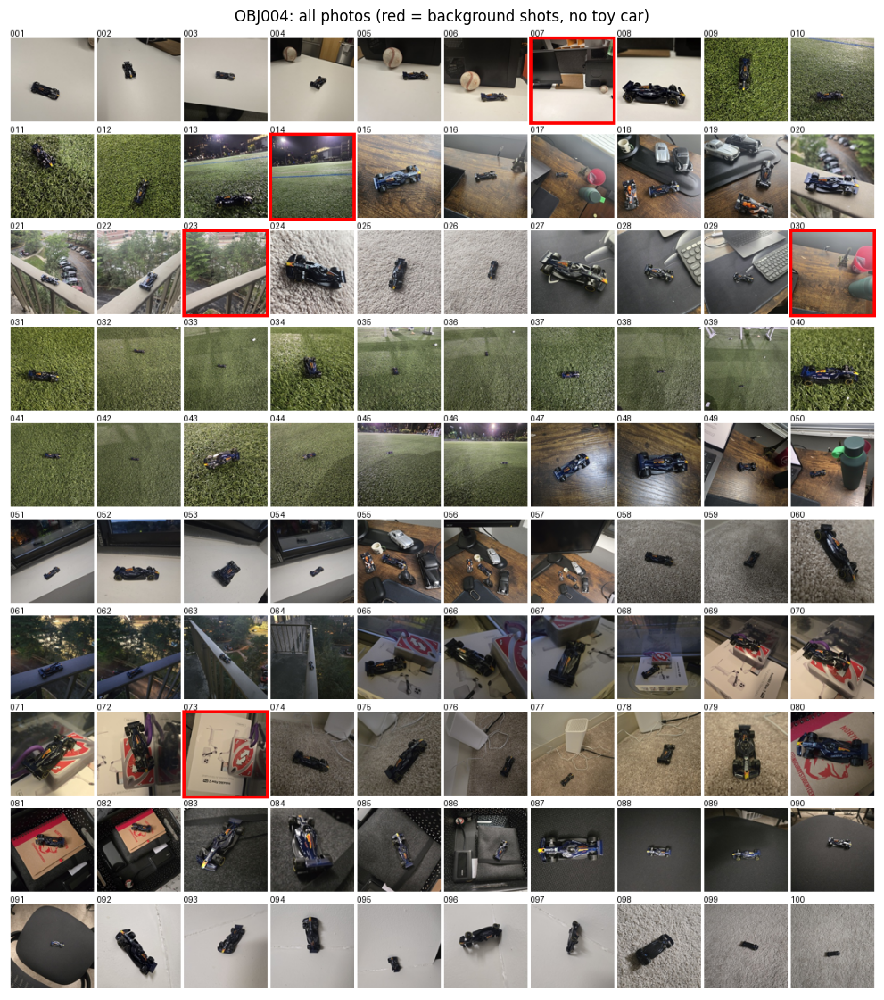

      old_name          new_name
OBJ004_007.jpg OBJ004_bg_001.jpg
OBJ004_014.jpg OBJ004_bg_002.jpg
OBJ004_023.jpg OBJ004_bg_003.jpg
OBJ004_030.jpg OBJ004_bg_004.jpg
OBJ004_073.jpg OBJ004_bg_005.jpg


In [9]:
obj004_dir = class_dir(4)
files004 = sorted(p.name for p in obj004_dir.iterdir() if p.suffix.lower() in IMG_EXT)

# contact sheet of all OBJ004 photos, candidates outlined in red (evidence for the report)
S, COLS = 110, 10
rows_n = math.ceil(len(files004) / COLS)
sheet = Image.new("RGB", (COLS * S, rows_n * (S + 12)), "white"); dr = ImageDraw.Draw(sheet)
for i, f in enumerate(files004):
    im = ImageOps.exif_transpose(Image.open(obj004_dir / f)).convert("RGB"); im.thumbnail((S - 4, S - 4))
    x, y = (i % COLS) * S, (i // COLS) * (S + 12)
    sheet.paste(im, (x + 2, y + 12)); dr.text((x + 2, y), re.sub(r"\D", "", f)[-3:], fill="black")
    if f in OBJ004_BG_FILES: dr.rectangle([x, y + 10, x + S - 1, y + S + 11], outline="red", width=4)
sheet.save(FIG_DIR / "obj004_contact_sheet.jpg", quality=90)
plt.figure(figsize=(14, 14)); plt.imshow(sheet); plt.axis("off")
plt.title("OBJ004: all photos (red = background shots, no toy car)"); plt.show()

renames = []
for i, f in enumerate(OBJ004_BG_FILES, 1):
    src, dst = obj004_dir / f, obj004_dir / f"OBJ004_bg_{i:03d}{Path(f).suffix}"
    assert src.exists(), f"missing {src}"
    src.rename(dst); renames.append({"old_name": f, "new_name": dst.name})
pd.DataFrame(renames).to_csv(SAVE_DIR / "obj004_bg_renames.csv", index=False)
print(pd.DataFrame(renames).to_string(index=False))

### 2.2 Exclude OBJ054

In [10]:
excluded = []
for cid in sorted(EXCLUDE_CLASSES):
    d = class_dir(int(re.sub(r"\D", "", cid)))
    n = sum(1 for p in d.rglob("*") if p.is_file())
    shutil.rmtree(d); excluded.append({"object_id": cid, "folder": d.name, "files_removed": n})
print(pd.DataFrame(excluded).to_string(index=False))
removed = [f"{e['folder']} ({e['files_removed']} files)" for e in excluded]

object_id        folder  files_removed
   OBJ054 images_OBJ054            100


### 2.3 Index, verify, separate background photos, de-duplicate

In [11]:
def obj_name(folder):              # "images_OBJ004" -> "OBJ004" (also "obj_4" -> "OBJ004")
    m = OBJ_RE.search(folder)
    return f"OBJ{int(m.group(1)):03d}" if m else folder

rows = []
for cdir in sorted(p for p in CLEAN_DIR.iterdir() if p.is_dir()):
    for p in sorted(cdir.rglob("*")):
        if p.is_file() and p.suffix.lower() in IMG_EXT and not p.name.startswith("."):
            rows.append({"path": str(p), "label": obj_name(cdir.name), "fname": p.name})
df = pd.DataFrame(rows)

def check(path):
    try:
        with Image.open(path) as im:
            size = im.size; im.verify()
        return True, size
    except Exception:
        return False, None
chk = [check(p) for p in df.path]
df["ok"] = [c[0] for c in chk]; df["size"] = [c[1] for c in chk]
not224 = df[df.ok & (df["size"] != (IMG_SIZE, IMG_SIZE))]
print("Images that are not 224 x 224 (resized to 224 x 224 whenever they are loaded):")
print(not224[["label", "fname", "size"]].to_string(index=False) if len(not224) else "  none")
not224[["label", "fname", "size"]].to_csv(SAVE_DIR / "non_224_images.csv", index=False)
print(f"Indexed {len(df)} images in {df.label.nunique()} classes | unreadable: {(~df.ok).sum()}")
df = df[df.ok].copy()

def md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()
df["md5"] = [md5(p) for p in df.path]
df["is_bg"] = df.fname.str.contains(BG_REGEX)

obj_df = df[~df.is_bg].copy()
bg_df  = df[df.is_bg].copy()
conflict = obj_df.groupby("md5").label.nunique()
conflict = set(conflict[conflict > 1].index)                       # same bytes under two labels: drop all copies
obj_df = obj_df[~obj_df.md5.isin(conflict)]
COPY_RE = r" ?\(\d+\)\.[^.]+$"                                     # Drive copies like "OBJ012_005 (1).jpg"
obj_df = obj_df.assign(_copy=obj_df.fname.str.contains(COPY_RE))
n0 = len(obj_df); obj_df = obj_df.sort_values(["_copy", "path"]).drop_duplicates("md5").drop(columns="_copy")
bg_df = bg_df.assign(_copy=bg_df.fname.str.contains(COPY_RE))
n0b = len(bg_df); bg_df = bg_df.sort_values(["_copy", "path"]).drop_duplicates("md5").drop(columns="_copy")
n_bg_dup = n0b - len(bg_df)
# A "background" file with the same bytes as an object photo actually shows the object (OBJ065's five bg files are
# copies of OBJ065_001/003/026/052/075, all showing the watch). Used as negatives they would teach "watch = background".
same_as_obj = bg_df[bg_df.md5.isin(set(obj_df.md5))]
bg_df = bg_df[~bg_df.md5.isin(set(obj_df.md5)) & ~bg_df.fname.isin(EXCLUDE_BG)]
print("Background files identical to an object photo (dropped from backgrounds):", sorted(same_as_obj.fname))
print("Background files excluded by hand (EXCLUDE_BG):", sorted(EXCLUDE_BG))
print(f"Background photos: {len(bg_df)} usable ({n_bg_dup} exact duplicates removed), from {bg_df.label.nunique()} classes")
print(f"Object photos:     {len(obj_df)} (after {n0 - len(obj_df)} same-class duplicates and {len(conflict)} cross-class conflicts removed)")
assert "OBJ004" in set(bg_df.label), "OBJ004 background photos were not picked up"
assert not set(EXCLUDE_CLASSES) & set(obj_df.label), "an excluded class is still present"
if CLASS_SUBSET is not None:
    obj_df = obj_df[obj_df.label.isin(CLASS_SUBSET)]; print("Using a subset of", obj_df.label.nunique(), "Object IDs")

counts = pd.DataFrame({"object_photos": obj_df.groupby("label").size(),
                       "background_photos": bg_df.groupby("label").size()}).fillna(0).astype(int)
counts.to_csv(SAVE_DIR / "class_counts_m2.csv")
print(f"Object photos per class: min {counts.object_photos.min()}, max {counts.object_photos.max()}")

Images that are not 224 x 224 (resized to 224 x 224 whenever they are loaded):
 label             fname         size
OBJ003    OBJ003_072.jpg   (224, 192)
OBJ023    OBJ023_001.JPG   (225, 224)
OBJ023 OBJ023_bg_001.JPG (2597, 2568)
Indexed 7243 images in 72 classes | unreadable: 0
Background files identical to an object photo (dropped from backgrounds): ['OBJ065_bg_001.jpg', 'OBJ065_bg_002.jpg', 'OBJ065_bg_003.jpg', 'OBJ065_bg_004.jpg', 'OBJ065_bg_005.jpg']
Background files excluded by hand (EXCLUDE_BG): ['OBJ035_bg_002.jpg', 'OBJ049_bg_001.jpg']
Background photos: 371 usable (7 exact duplicates removed), from 71 classes
Object photos:     6842 (after 16 same-class duplicates and 0 cross-class conflicts removed)
Object photos per class: min 89, max 106


## 3. Bounding boxes: auto-labelling with two open-vocabulary detectors
The dataset gives each photo a class (its folder) but no box. Each photo is shown to **YOLO-World** and **YOLOE**, both prompted with a short text name of the photo's own object (e.g. "tennis ball" for OBJ027), and each returns its most confident box.

**Decision rule (fixed before training):**

| Case | Result |
|---|---|
| Both detectors find a box and the boxes agree (IoU ≥ 0.5) | **accepted**: the box is the average of the two |
| Agreed box covers < 1 % of the photo | left out: *too small / far away* |
| Boxes disagree (IoU < 0.5), e.g. one picked another item in a cluttered scene | left out: *disagree* |
| Only one detector finds the object, or neither | left out: *one model only* / *no detection* |
| A class keeps fewer than 20 photos | its *one model only* photos with confidence ≥ 0.6 are added back (marked *accepted_single*) |
| You reject a photo after looking at the check figures | left out: *manual* (add its file name to `MANUAL_DROP`) |

**Object names (text prompts).** If the shared sheet `Milestone-1 _ OBJECTS (1).xlsx` is in `SAVE_DIR` (or anywhere in My Drive), its `OBJECT_NAME` is used, plus the TA description from `visual_review_notes.csv` if present; both are given to the detectors as prompts for the same object. Without the sheet, short names written from the photos are used (`DEFAULT_NAMES`). An `object_names.csv` (`object_id,name`) in `SAVE_DIR` overrides both. Better names give better boxes.

Raw detections are cached on Drive, so changing the rule or `MANUAL_DROP` and re-running is fast.

In [12]:
DEFAULT_NAMES = {
 "OBJ001": "basketball", "OBJ002": "plastic water bottle", "OBJ003": "black notebook",
 "OBJ004": "toy race car", "OBJ005": "computer mouse", "OBJ006": "yellow toy figure",
 "OBJ007": "red apple", "OBJ008": "cat", "OBJ009": "black bluetooth speaker",
 "OBJ010": "sneakers", "OBJ011": "red and white travel cup", "OBJ012": "white keyboard",
 "OBJ013": "phone in a clear case", "OBJ014": "sunglasses", "OBJ015": "black tumbler with straw",
 "OBJ016": "portable hard drive", "OBJ017": "game controller", "OBJ018": "rubik's cube",
 "OBJ019": "bonsai tree in a pot", "OBJ020": "earbuds case", "OBJ021": "white bunny plush toy",
 "OBJ022": "acoustic guitar", "OBJ023": "beaded bracelet", "OBJ024": "plush doll",
 "OBJ025": "silver wristwatch", "OBJ026": "baseball cap", "OBJ027": "tennis ball",
 "OBJ028": "banana", "OBJ029": "orange", "OBJ030": "tennis racket",
 "OBJ031": "UNO card box", "OBJ032": "red box", "OBJ033": "rubber duck",
 "OBJ034": "table tennis paddle", "OBJ035": "badminton racket", "OBJ036": "pencil case",
 "OBJ037": "candle jar", "OBJ038": "glass perfume bottle", "OBJ039": "scissors",
 "OBJ040": "hair claw clip", "OBJ041": "desk fan", "OBJ042": "mouth guard case",
 "OBJ043": "swimming goggles", "OBJ044": "small figurine", "OBJ045": "sunglasses",
 "OBJ046": "apple watch", "OBJ047": "black backpack", "OBJ048": "power bank",
 "OBJ049": "pickleball paddle", "OBJ050": "hairbrush", "OBJ051": "tissue box",
 "OBJ052": "spoon", "OBJ053": "lotion pump bottle", "OBJ055": "calculator",
 "OBJ056": "paper shopping bag", "OBJ057": "black remote control", "OBJ058": "small stool",
 "OBJ059": "pink comb", "OBJ060": "sleep eye mask", "OBJ061": "card holder wallet",
 "OBJ062": "headphones", "OBJ063": "water bottle", "OBJ064": "small black device",
 "OBJ065": "wristwatch", "OBJ066": "hair oil bottle", "OBJ067": "black wallet",
 "OBJ068": "neck pillow", "OBJ069": "red knife", "OBJ070": "astronaut toy",
 "OBJ071": "sloth plush toy", "OBJ072": "dog", "OBJ073": "ceramic bowl",
}
def find_file(name):
    # looks in the results folder, then the top of My Drive, then one folder level down
    for base in (SAVE_DIR, Path("/content/drive/MyDrive")):
        if (base / name).exists(): return base / name
    hits = sorted(Path("/content/drive/MyDrive").glob(f"*/{name}"))
    return hits[0] if hits else None

NAMES, TA_NOTES, name_source = dict(DEFAULT_NAMES), {}, "DEFAULT_NAMES (written from the photos)"
excel = find_file(EXCEL_NAME)
if excel is not None:
    xl = pd.read_excel(excel); xl.columns = xl.columns.str.strip()
    NAMES.update({str(i).strip(): str(n).strip() for i, n in zip(xl.OBJECT_ID, xl.OBJECT_NAME) if pd.notna(n)})
    name_source = f"shared sheet {excel.name}"
    # instructor: use the FINAL Object IDs from the shared sheet -> check they match the dataset folders
    sheet_ids = {str(i).strip() for i in xl.OBJECT_ID if pd.notna(i)}
    folder_ids = set(obj_df.label) | set(EXCLUDE_CLASSES)
    print("Object IDs in the dataset but not in the sheet:", sorted(folder_ids - sheet_ids) or "none")
    print("Object IDs in the sheet but not in the dataset:", sorted(sheet_ids - folder_ids) or "none")
    if "SECTION" in " ".join(map(str, xl.columns)).upper() or xl.astype(str).apply(lambda col: col.str.contains("SECTION-01")).any().any():
        print("(The sheet marks Section 1 objects; set CLASS_SUBSET to train on that subset only.)")
notes_file = find_file(NOTES_NAME)
if notes_file is not None:
    nt = pd.read_csv(notes_file)
    TA_NOTES = {str(i).strip(): str(o).strip() for i, o in zip(nt.object_id, nt.object) if pd.notna(o)}
if OBJECT_NAMES_CSV.exists():
    sheet = pd.read_csv(OBJECT_NAMES_CSV)
    NAMES.update({str(r.object_id).strip(): str(r.name).strip() for r in sheet.itertuples()})
    name_source = f"{OBJECT_NAMES_CSV.name}"
print("Object names from:", name_source, "| TA descriptions:", len(TA_NOTES))

LABEL_IDS = sorted(obj_df.label.unique())
missing = [c for c in LABEL_IDS if c not in NAMES]
assert not missing, f"no text prompt for {missing}: add them to DEFAULT_NAMES or object_names.csv"
# prompts per Object ID: the name, plus the TA description when it adds something
PROMPTS = {c: list(dict.fromkeys(p for p in (NAMES[c], TA_NOTES.get(c, "")) if p)) for c in LABEL_IDS}
pd.DataFrame({"object_id": LABEL_IDS, "name": [NAMES[c] for c in LABEL_IDS],
              "prompts": [" | ".join(PROMPTS[c]) for c in LABEL_IDS]}).to_csv(SAVE_DIR / "prompts_used.csv", index=False)
print(f"{len(LABEL_IDS)} Object IDs to label, e.g.", {c: PROMPTS[c] for c in LABEL_IDS[:4]})

Object names from: DEFAULT_NAMES (written from the photos) | TA descriptions: 0
72 Object IDs to label, e.g. {'OBJ001': ['basketball'], 'OBJ002': ['plastic water bottle'], 'OBJ003': ['black notebook'], 'OBJ004': ['toy race car']}


In [13]:
def load_photo(path):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    return im if im.size == (IMG_SIZE, IMG_SIZE) else im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

def top_box(r):
    if r.boxes is None or len(r.boxes) == 0:
        return [np.nan] * 5
    k = int(r.boxes.conf.argmax())
    return [float(v) for v in r.boxes.xyxy[k].tolist()] + [float(r.boxes.conf[k])]

def set_prompt(model, key, names):
    if key == "yoloe":
        try:
            model.set_classes(names)                                  # ultralytics >= 8.4 (YOLOE-26)
        except Exception:
            model.set_classes(names, model.get_text_pe(names))        # older ultralytics versions
    else:
        model.set_classes(names)

def run_labeler(key, weights):
    tag = hashlib.md5(json.dumps(PROMPTS, sort_keys=True).encode()).hexdigest()[:8]   # new prompts -> new cache
    cache = SAVE_DIR / f"autolabels_{key}_{tag}.csv"
    if cache.exists():
        d = pd.read_csv(cache)
        if set(obj_df.path).issubset(set(d.path)):
            print(f"{key}: using cached detections ({cache.name})"); return d
    from ultralytics import YOLOWorld, YOLOE
    model = YOLOWorld(weights) if key == "world" else YOLOE(weights)
    rows, t0 = [], time.time()
    for label, g in obj_df.groupby("label"):
        set_prompt(model, key, PROMPTS[label])
        paths = list(g.path)
        for i in range(0, len(paths), 16):
            chunk = paths[i:i + 16]
            res = model.predict([load_photo(p) for p in chunk], imgsz=LABEL_IMGSZ, conf=LABEL_MIN_CONF, verbose=False)
            for p, r in zip(chunk, res):
                rows.append(dict(zip(["path", "x1", "y1", "x2", "y2", "conf"], [p] + top_box(r))))
    d = pd.DataFrame(rows); d.to_csv(cache, index=False)
    print(f"{key}: labelled {len(d)} photos in {time.time() - t0:.0f} s, {d.conf.notna().mean():.1%} with a detection")
    return d

RAW = {k: run_labeler(k, w) for k, w in LABELERS.items()}

world: using cached detections (autolabels_world_0ca50bdc.csv)
yoloe: using cached detections (autolabels_yoloe_0ca50bdc.csv)


In [14]:
def box_iou(a, b):
    iw, ih = min(a[2], b[2]) - max(a[0], b[0]), min(a[3], b[3]) - max(a[1], b[1])
    if iw <= 0 or ih <= 0: return 0.0
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

(ka, kb) = list(LABELERS)
lab = obj_df[["path", "label", "fname"]].merge(RAW[ka].add_prefix(f"{ka}_").rename(columns={f"{ka}_path": "path"}), on="path") \
                                       .merge(RAW[kb].add_prefix(f"{kb}_").rename(columns={f"{kb}_path": "path"}), on="path")
BOX = lambda r, k: [r[f"{k}_x1"], r[f"{k}_y1"], r[f"{k}_x2"], r[f"{k}_y2"]]

def decide(r):
    ha, hb = not np.isnan(r[f"{ka}_conf"]), not np.isnan(r[f"{kb}_conf"])
    if r.fname in MANUAL_DROP:      return "manual", None, np.nan
    if not ha and not hb:           return "no_detection", None, np.nan
    if ha != hb:                    return "one_model_only", None, np.nan
    v = box_iou(BOX(r, ka), BOX(r, kb))
    if v < AGREE_IOU:               return "disagree", None, v
    b = [(x + y) / 2 for x, y in zip(BOX(r, ka), BOX(r, kb))]
    if (b[2] - b[0]) * (b[3] - b[1]) < MIN_BOX_FRAC * IMG_SIZE ** 2: return "too_small", b, v
    return "accepted", b, v

out = [decide(r) for _, r in lab.iterrows()]
lab["status"] = [o[0] for o in out]; lab["box"] = [o[1] for o in out]; lab["agree_iou"] = [o[2] for o in out]

# classes left with too few photos: add back confident single-labeller boxes
for label, g in lab.groupby("label"):
    if (g.status == "accepted").sum() < MIN_PHOTOS_PER_CLASS:
        for i, r in g[g.status == "one_model_only"].iterrows():
            k = ka if not np.isnan(r[f"{ka}_conf"]) else kb
            b = BOX(r, k)
            if r[f"{k}_conf"] >= SINGLE_MIN_CONF and (b[2] - b[0]) * (b[3] - b[1]) >= MIN_BOX_FRAC * IMG_SIZE ** 2:
                lab.at[i, "status"] = "accepted_single"; lab.at[i, "box"] = b

KEEP = {"accepted", "accepted_single"}
summary_lab = lab.status.value_counts().rename("photos").to_frame()
summary_lab["share"] = (summary_lab.photos / len(lab)).round(3)
print(summary_lab.to_string())
print(f"Mean IoU between the two labellers on accepted photos: {lab.loc[lab.status == 'accepted', 'agree_iou'].mean():.3f}")
per_class = lab.assign(kept=lab.status.isin(KEEP)).groupby("label").agg(photos=("kept", "size"), kept=("kept", "sum"))
per_class["kept_share"] = (per_class.kept / per_class.photos).round(2)
print(f"Kept photos per class: min {per_class.kept.min()} ({per_class.kept.idxmin()}), median {int(per_class.kept.median())}")
print("Classes keeping the fewest photos:\n", per_class.sort_values("kept").head(8).to_string())

lab_out = lab[["label", "fname", "path", "status", "agree_iou", f"{ka}_conf", f"{kb}_conf"]].copy()
lab_out[["x1", "y1", "x2", "y2"]] = pd.DataFrame([b if isinstance(b, (list, tuple)) else [np.nan] * 4 for b in lab.box], index=lab.index)
lab_out.to_csv(SAVE_DIR / "labels_single_photos.csv", index=False)
summary_lab.to_csv(SAVE_DIR / "labelling_summary.csv"); per_class.to_csv(SAVE_DIR / "labelling_per_class.csv")

                 photos  share
status                        
accepted           3664  0.536
one_model_only     1627  0.238
no_detection        903  0.132
disagree            462  0.068
accepted_single     124  0.018
too_small            62  0.009
Mean IoU between the two labellers on accepted photos: 0.930
Kept photos per class: min 4 (OBJ025), median 56
Classes keeping the fewest photos:
         photos  kept  kept_share
label                           
OBJ025      94     4        0.04
OBJ038      95     4        0.04
OBJ043      95     5        0.05
OBJ046      95     6        0.06
OBJ040      95     7        0.07
OBJ050      95     7        0.07
OBJ049      99     9        0.09
OBJ020      95     9        0.09


### 3.1 Check the boxes by eye
Blue = YOLO-World, orange = YOLOE, **green = final box**. Look through both figures; if an accepted box is wrong (wrong item, only part of the object), add the file name to `MANUAL_DROP` in the settings cell and re-run from §3 (detections are cached, so it is quick). For the report, state how many photos were checked and how many were rejected by hand.

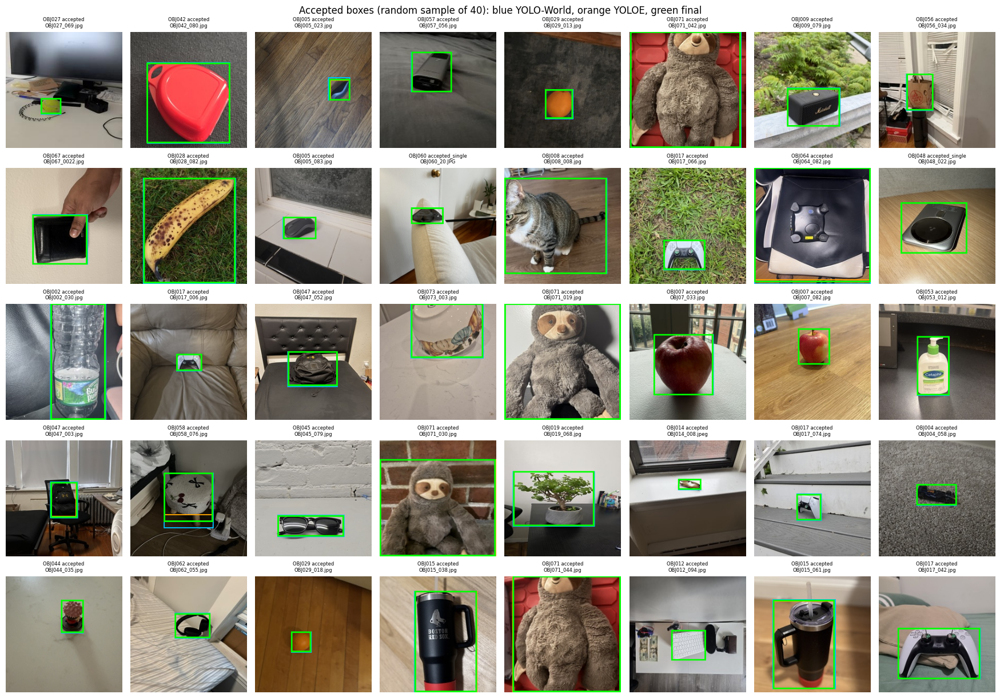

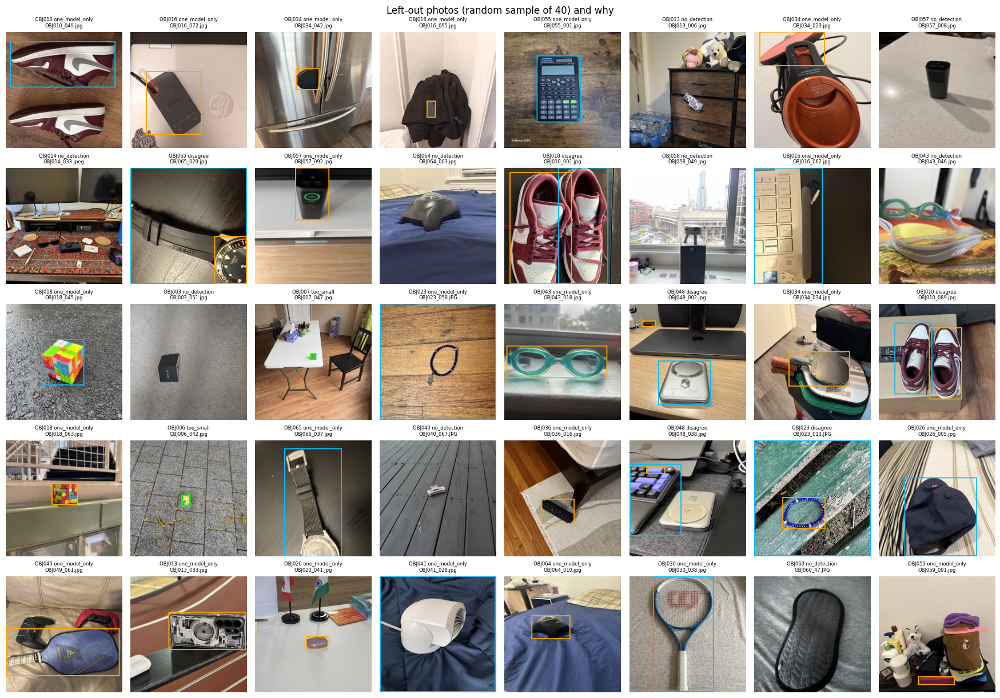

Object photos with a reliable box: 3788 in 72 classes


In [15]:
def show_label_grid(rows_df, title, fname, n=40, cols=8):
    rows_df = rows_df.sample(min(n, len(rows_df)), random_state=SEED) if len(rows_df) else rows_df
    if not len(rows_df): print("nothing to show for", title); return
    nr = math.ceil(len(rows_df) / cols)
    fig, axes = plt.subplots(nr, cols, figsize=(2.2 * cols, 2.5 * nr))
    for ax, (_, r) in zip(np.ravel(axes), rows_df.iterrows()):
        im = load_photo(r.path); d = ImageDraw.Draw(im)
        safe = lambda b: [min(b[0], b[2]), min(b[1], b[3]), max(b[0], b[2]), max(b[1], b[3])]
        for k, col in ((ka, "deepskyblue"), (kb, "orange")):
            if not np.isnan(r[f"{k}_conf"]): d.rectangle(safe(BOX(r, k)), outline=col, width=2)
        if isinstance(r.box, (list, tuple)): d.rectangle(safe(r.box), outline="lime", width=3)
        ax.imshow(im); ax.set_title(f"{r.label} {r.status}\n{r.fname}", fontsize=6)
    for ax in np.ravel(axes): ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=130); plt.show()

show_label_grid(lab[lab.status.isin(KEEP)], "Accepted boxes (random sample of 40): blue YOLO-World, orange YOLOE, green final",
                "labels_accepted_sample.png")
show_label_grid(lab[~lab.status.isin(KEEP)], "Left-out photos (random sample of 40) and why", "labels_rejected_sample.png")
obj_df = obj_df.merge(lab[["path", "status", "box"]], on="path")
obj_df = obj_df[obj_df.status.isin(KEEP)].reset_index(drop=True)
print(f"Object photos with a reliable box: {len(obj_df)} in {obj_df.label.nunique()} classes")

## 4. Split the labelled single photos 70 / 15 / 15 (seed 42) *before* building grids
Grids for validation and test are built **only** from validation and test photos, so no source photo appears in more than one split. Background photos are split the same way.

In [16]:
obj_df = obj_df.sort_values("path").reset_index(drop=True)
BOXES = dict(zip(obj_df.path, obj_df.box))                  # photo -> [x1, y1, x2, y2] in 224 x 224 pixels
CLASSES = sorted(obj_df.label.unique())                  # "OBJ001" ... "OBJ073"
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
obj_df["cls"] = obj_df.label.map(CLASS_TO_IDX)

tr, tmp = train_test_split(obj_df, test_size=0.30, stratify=obj_df.label, random_state=SEED)
# Remove stratify from the validation/test split because some classes have only 1 member in the 30% subset
va, te  = train_test_split(tmp,    test_size=0.50, random_state=SEED)
SINGLE = {"train": tr.reset_index(drop=True), "val": va.reset_index(drop=True), "test": te.reset_index(drop=True)}

bg_df = bg_df.sort_values("path").reset_index(drop=True)
btr, btmp = train_test_split(bg_df, test_size=0.30, random_state=SEED)
bva, bte  = train_test_split(btmp,  test_size=0.50, random_state=SEED)
BG = {"train": list(btr.path), "val": list(bva.path), "test": list(bte.path)}

for s in SINGLE:
    SINGLE[s].drop(columns=["box"]).to_csv(SAVE_DIR / f"single_{s}_split.csv", index=False)
    print(f"{s:5s}: {len(SINGLE[s]):5d} object photos ({SINGLE[s].label.nunique()} classes) | {len(BG[s]):3d} background photos")
paths = [set(SINGLE[s].path) | set(BG[s]) for s in SINGLE]
assert not (paths[0] & paths[1] or paths[0] & paths[2] or paths[1] & paths[2]), "leak between splits"
Path(SAVE_DIR, "classes.json").write_text(json.dumps(CLASSES))

train:  2651 object photos (72 classes) | 259 background photos
val  :   568 object photos (69 classes) |  56 background photos
test :   569 object photos (71 classes) |  56 background photos


720

## 5. Grid generator
Each grid image places 224 × 224 photos **side by side** (no resizing, no gaps). A box is the photo's auto-labelled object box shifted to its cell.

| Grid (rows × cols) | Cells | Image size | Share of images |
|---|---|---|---|
| 2 × 2 | 4 | 448 × 448 | 15 % |
| 3 × 3 | 9 | 672 × 672 | 25 % |
| 4 × 4 | 16 | 896 × 896 | 25 % |
| 4 × 5 (the instructor's "5 × 4") | 20 | 1120 × 896 | 15 % |
| 5 × 5 | 25 | 1120 × 1120 | 20 % |
| 1 × 1 (solo) | 1 | 224 × 224 | extra, see below |

* Each cell holds an object photo, or (10 % chance) an **unlabeled background photo**, so the model learns that not every cell contains an object. **8 %** of images are background-only (empty label file).
* Each Object ID appears at most once per image (each ID is one physical object); classes and photos are drawn in rotation so every ID appears about equally often.
* **Augmentation, training grids only** (validation and test grids use the photos unchanged):
  * per photo: horizontal flip (50 %, the box is mirrored too), brightness × 0.6–1.4, contrast × 0.7–1.3, saturation × 0.6–1.4 (80 %), dark gamma 1.5–2.5 (10 %), and one of: Gaussian blur (8 %), **motion blur** (8 %), **defocus blur** (6 %) or low-quality downscale + JPEG (8 %);
  * per grid: whole-image low quality on 15 % of training grids (downscale 1.5–4×, darker, blur, JPEG 15–50).
  * No crops or rotations at this stage, so boxes stay exact. YOLO adds its own geometric augmentation during training (§7).
* **Solo images (1 × 1):** 300 / 60 / 60 extra images with one photo alone (8 % background-only), so the model also handles a single object filling the view, like a normal phone photo.

In [17]:
import cv2

def motion_blur(im, k, angle):
    # camera shake / moving object: blur along a line of length k
    kernel = np.zeros((k, k), np.float32); kernel[k // 2, :] = 1.0
    kernel = cv2.warpAffine(kernel, cv2.getRotationMatrix2D((k / 2 - 0.5, k / 2 - 0.5), angle, 1.0), (k, k))
    return Image.fromarray(cv2.filter2D(np.asarray(im), -1, kernel / kernel.sum()))

def defocus_blur(im, r):
    # out of focus: average over a disc of radius r
    k = 2 * r + 1; kernel = np.zeros((k, k), np.float32); cv2.circle(kernel, (r, r), r, 1.0, -1)
    return Image.fromarray(cv2.filter2D(np.asarray(im), -1, kernel / kernel.sum()))

def jpeg(im, q):
    buf = io.BytesIO(); im.save(buf, "JPEG", quality=int(q)); buf.seek(0)
    return Image.open(buf).convert("RGB")

def augment_tile(im, box, rng):
    # photometric changes + horizontal flip; box (224-pixel coords) is mirrored with the photo
    if rng.random() < 0.5:
        im = ImageOps.mirror(im)
        if box is not None: box = [IMG_SIZE - box[2], box[1], IMG_SIZE - box[0], box[3]]
    if rng.random() < 0.8:
        im = ImageEnhance.Brightness(im).enhance(rng.uniform(0.6, 1.4))
        im = ImageEnhance.Contrast(im).enhance(rng.uniform(0.7, 1.3))
        im = ImageEnhance.Color(im).enhance(rng.uniform(0.6, 1.4))
    if rng.random() < 0.10:                                          # dark photo (gamma)
        im = Image.fromarray((255 * (np.asarray(im) / 255.0) ** rng.uniform(1.5, 2.5)).astype(np.uint8))
    r = rng.random()
    if r < 0.08:
        im = im.filter(ImageFilter.GaussianBlur(rng.uniform(0.5, 1.8)))
    elif r < 0.16:
        im = motion_blur(im, int(rng.choice([5, 7, 9, 11])), rng.uniform(0, 180))
    elif r < 0.22:
        im = defocus_blur(im, int(rng.choice([2, 3])))
    elif r < 0.30:
        f = rng.uniform(2, 4)
        im = im.resize((int(IMG_SIZE / f), int(IMG_SIZE / f)), Image.BILINEAR).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        im = jpeg(im, rng.integers(15, 40))
    return im, box

def degrade_canvas(im, rng):
    w, h = im.size; f = rng.uniform(1.5, 4.0)
    im = im.resize((max(8, int(w / f)), max(8, int(h / f))), Image.BILINEAR).resize((w, h), Image.BILINEAR)
    im = ImageEnhance.Brightness(im).enhance(rng.uniform(0.55, 1.0))
    if rng.random() < 0.5: im = im.filter(ImageFilter.GaussianBlur(rng.uniform(0.5, 1.5)))
    return jpeg(im, rng.integers(15, 50))

def make_grid(items, shape):
    # items: list of (224x224 PIL photo, box or None, cls or None), one per cell in reading order
    rows, cols = shape
    canvas = Image.new("RGB", (cols * IMG_SIZE, rows * IMG_SIZE)); boxes = []
    for idx, (tile, box, c) in enumerate(items):
        r, k = divmod(idx, cols); x0, y0 = k * IMG_SIZE, r * IMG_SIZE
        canvas.paste(tile, (x0, y0))
        if c is not None:
            boxes.append((c, x0 + box[0], y0 + box[1], x0 + box[2], y0 + box[3]))
    return canvas, boxes

class BalancedSampler:
    # Cycles through classes (shuffled) and through each class's photos, so IDs and photos are used evenly.
    def __init__(self, single_df, rng):
        self.rng = rng
        self.by_cls = {int(c): list(g.path) for c, g in single_df.groupby("cls")}
        self.cls_q, self.img_q = [], {c: [] for c in self.by_cls}
    def classes(self, k):
        out, held = [], []
        while len(out) < k:
            if not self.cls_q: self.cls_q = [int(c) for c in self.rng.permutation(list(self.by_cls))]
            c = self.cls_q.pop()
            (held if c in out else out).append(c)
        self.cls_q.extend(held)
        return out
    def photo(self, c):
        if not self.img_q[c]: self.img_q[c] = [self.by_cls[c][i] for i in self.rng.permutation(len(self.by_cls[c]))]
        return self.img_q[c].pop()

def draw_k(rng, dist):
    keys = list(dist); p = np.array([dist[k] for k in keys], float)
    return keys[rng.choice(len(keys), p=p / p.sum())]

## 6. Generate the grid dataset (≥ 100 multi-object images per member)
Each member generates their own share with their own seed; file names start with the member's initials (e.g. `TS_train_0001.jpg`). `grids_manifest.csv` records, for every image, its author, grid size, Object IDs and source photos. Labels are YOLO format (`class x_center y_center width height`, normalised by the image's own width and height). The finished dataset is zipped to your Drive so later sessions skip this step.

In [18]:
SPLITS = ["train", "val", "test"]
DATASET_ZIP = SAVE_DIR / f"yolo_grids_{'quick' if QUICK_TEST else 'full'}.zip"
GRID_LIST = list(GRID_SHAPES)

def generate_dataset():
    if YOLO_DIR.exists(): shutil.rmtree(YOLO_DIR)
    manifest = []
    for si, split in enumerate(SPLITS):
        (YOLO_DIR / "images" / split).mkdir(parents=True); (YOLO_DIR / "labels" / split).mkdir(parents=True)
        sampler = BalancedSampler(SINGLE[split], np.random.default_rng(SEED + 100 * si))
        aug = split == "train"
        for mi, (ini, member) in enumerate(MEMBERS.items()):
            rng = np.random.default_rng(SEED + 1000 * (mi + 1) + si)
            n = N_PER_MEMBER[split]; n_neg = int(round(n * NEG_FRAC))
            kinds = ["neg"] * n_neg + ["pos"] * (n - n_neg)
            kinds = [kinds[i] for i in rng.permutation(n)]
            for j, kind in enumerate(kinds, 1):
                name = f"{ini}_{split}_{j:04d}"
                shape = GRID_LIST[rng.choice(len(GRID_LIST), p=np.array(list(GRID_SHAPES.values())) / sum(GRID_SHAPES.values()))]
                n_cells = shape[0] * shape[1]
                is_bg = [True] * n_cells if kind == "neg" else list(rng.random(n_cells) < BG_CELL_P)
                if kind == "pos" and all(is_bg): is_bg[0] = False
                cls_list = sampler.classes(sum(not b for b in is_bg)) if kind == "pos" else []
                items, srcs, bg_srcs, ci = [], [], [], 0
                for b in is_bg:
                    if b:
                        p = BG[split][rng.integers(len(BG[split]))]; bg_srcs.append(p)
                        tile, _ = augment_tile(load_photo(p), None, rng) if aug else (load_photo(p), None)
                        items.append((tile, None, None))
                    else:
                        c = cls_list[ci]; ci += 1
                        p = sampler.photo(c); srcs.append(p)
                        tile, box = augment_tile(load_photo(p), list(BOXES[p]), rng) if aug else (load_photo(p), list(BOXES[p]))
                        items.append((tile, box, c))
                canvas, boxes = make_grid(items, shape)
                degraded = aug and rng.random() < CANVAS_LOWQ_P
                if degraded: canvas = degrade_canvas(canvas, rng)
                W, H = canvas.size
                canvas.save(YOLO_DIR / "images" / split / f"{name}.jpg", quality=92)
                with open(YOLO_DIR / "labels" / split / f"{name}.txt", "w") as f:
                    for c, x1, y1, x2, y2 in boxes:
                        f.write(f"{c} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}\n")
                manifest.append({"image": f"{name}.jpg", "split": split, "member": member, "kind": kind,
                                 "grid": f"{shape[1]}x{shape[0]}", "width": W, "height": H, "n_objects": len(boxes),
                                 "degraded": int(degraded), "ids": " ".join(CLASSES[b[0]] for b in boxes),
                                 "source_photos": "|".join(Path(p).name for p in srcs),
                                 "background_photos": "|".join(Path(p).name for p in bg_srcs)})
        # solo (1 x 1) images: one photo alone, shared across members
        rng = np.random.default_rng(SEED + 7 + si)
        cls_cycle = []
        for j in range(1, N_SOLO[split] + 1):
            name = f"SOLO_{split}_{j:04d}"
            if rng.random() < NEG_FRAC:
                p = BG[split][rng.integers(len(BG[split]))]; srcs, bg_srcs = [], [p]
                tile, box = augment_tile(load_photo(p), None, rng) if aug else (load_photo(p), None); c = None
            else:
                if not cls_cycle: cls_cycle = [int(x) for x in rng.permutation(sorted(SINGLE[split].cls.unique()))]
                c = cls_cycle.pop(); p = sampler.photo(c); srcs, bg_srcs = [p], []
                tile, box = augment_tile(load_photo(p), list(BOXES[p]), rng) if aug else (load_photo(p), list(BOXES[p]))
            canvas, boxes = make_grid([(tile, box, c)], (1, 1))
            W, H = canvas.size
            canvas.save(YOLO_DIR / "images" / split / f"{name}.jpg", quality=92)
            with open(YOLO_DIR / "labels" / split / f"{name}.txt", "w") as f:
                for c_, x1, y1, x2, y2 in boxes:
                    f.write(f"{c_} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}\n")
            manifest.append({"image": f"{name}.jpg", "split": split, "member": "solo (shared)",
                             "kind": "neg" if c is None else "pos", "grid": "1x1", "width": W, "height": H,
                             "n_objects": len(boxes), "degraded": 0, "ids": " ".join(CLASSES[b[0]] for b in boxes),
                             "source_photos": "|".join(Path(q).name for q in srcs),
                             "background_photos": "|".join(Path(q).name for q in bg_srcs)})
        print(f"{split}: done")
    man = pd.DataFrame(manifest)
    man.to_csv(YOLO_DIR / "grids_manifest.csv", index=False)
    shutil.make_archive(str(DATASET_ZIP.with_suffix("")), "zip", YOLO_DIR)
    return man

if REGENERATE or not DATASET_ZIP.exists():
    t0 = time.time(); manifest = generate_dataset(); print(f"Generated in {time.time() - t0:.0f} s, saved {DATASET_ZIP.name}")
else:
    if YOLO_DIR.exists(): shutil.rmtree(YOLO_DIR)
    shutil.unpack_archive(str(DATASET_ZIP), str(YOLO_DIR)); manifest = pd.read_csv(YOLO_DIR / "grids_manifest.csv")
    print("Loaded saved dataset", DATASET_ZIP.name)
shutil.copy(YOLO_DIR / "grids_manifest.csv", SAVE_DIR / "grids_manifest.csv")

# YOLOE fine-tuning turns the class NAMES into text embeddings for its head, so the names must be real words
# ("tennis ball"), not "OBJ027". Duplicated names (two pairs of sunglasses) get their Object ID added.
_dup = pd.Series([NAMES[c] for c in CLASSES]).duplicated(keep=False).values
TRAIN_NAMES = [f"{NAMES[c]} {c}" if d else NAMES[c] for c, d in zip(CLASSES, _dup)]
DATA_YAML = YOLO_DIR / "data.yaml"
DATA_YAML.write_text("path: " + str(YOLO_DIR) + "\ntrain: images/train\nval: images/val\ntest: images/test\n"
                     + "names:\n" + "".join(f"  {i}: {json.dumps(n)}\n" for i, n in enumerate(TRAIN_NAMES)))
pd.DataFrame({"class_index": range(len(CLASSES)), "object_id": CLASSES, "training_name": TRAIN_NAMES}) \
  .to_csv(SAVE_DIR / "class_index_to_object_id.csv", index=False)
print("class 0..2:", list(zip(CLASSES[:3], TRAIN_NAMES[:3])), "| predictions are mapped back to Object IDs")
print(DATA_YAML.read_text()[:200], "...")

Loaded saved dataset yolo_grids_full.zip
class 0..2: [('OBJ001', 'basketball'), ('OBJ002', 'plastic water bottle'), ('OBJ003', 'black notebook')] | predictions are mapped back to Object IDs
path: /content/m2_work/yolo_dataset
train: images/train
val: images/val
test: images/test
names:
  0: "basketball"
  1: "plastic water bottle"
  2: "black notebook"
  3: "toy race car"
  4: "computer  ...


                           images           multi_object           background_only           objects           
split                        test train val         test train val            test train val    test train  val
member                                                                                                         
Mukul Sridar Haladhi           40   300  40           37   276  37               3    24   3     488  3770  545
Praniti Sunil Kale             40   300  40           37   276  37               3    24   3     565  3514  460
Santhoshkumar Chandrasekar     40   300  40           37   276  37               3    24   3     413  3671  479
Tanmayi Shurpali               40   300  40           37   276  37               3    24   3     523  3701  478
solo (shared)                  60   300  60            0     0   0               7    18   5      53   282   55

Multi-object images per member: {'Mukul Sridar Haladhi': 350, 'Praniti Sunil Kale': 350, 'Santhoshkumar

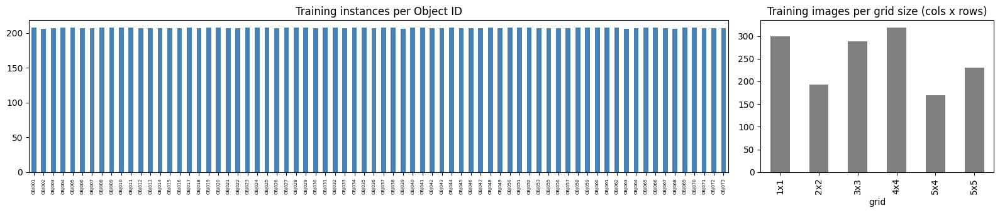

In [19]:
# Dataset summary: requirement check (>= 100 multi-object images per member), grid sizes, leakage check
for col in ("source_photos", "background_photos", "ids"):
    manifest[col] = manifest[col].fillna("").astype(str)
summary = manifest.assign(multi=manifest.n_objects >= 2, neg=manifest.kind == "neg").groupby(["member", "split"]).agg(
    images=("image", "size"), multi_object=("multi", "sum"), background_only=("neg", "sum"),
    objects=("n_objects", "sum")).unstack("split")
print(summary.to_string())
per_member_multi = manifest[(manifest.n_objects >= 2) & (manifest.grid != "1x1")].groupby("member").size()
print("\nMulti-object images per member:", per_member_multi.to_dict())
assert (per_member_multi >= 100).all() or QUICK_TEST, "a member has fewer than 100 multi-object images"
print("\nGrid sizes (cols x rows) per split:\n", pd.crosstab(manifest.grid, manifest.split).to_string())

name_to_split = {Path(p).name: s for s in SPLITS for p in list(SINGLE[s].path) + BG[s]}
for s in SPLITS:
    rows = manifest[manifest.split == s]
    used = set("|".join(rows.source_photos + "|" + rows.background_photos).split("|")) - {""}
    unknown = [u for u in used if u not in name_to_split]
    assert not unknown, f"saved dataset is stale ({unknown[:3]}): set REGENERATE = True and rerun from §6"
    wrong = [u for u in used if name_to_split[u] != s]
    assert not wrong, f"{s} grids use photos from another split, e.g. {wrong[:3]}"
print("Leakage check passed: every grid uses only photos from its own split.")
print("Training grids with whole-image low-quality augmentation:", int(manifest.loc[manifest.split == "train", "degraded"].sum()))

inst = pd.DataFrame({s: pd.Series(" ".join(manifest.loc[manifest.split == s, "ids"]).split()).value_counts()
                     for s in SPLITS}).reindex(CLASSES).fillna(0).astype(int)
inst.to_csv(SAVE_DIR / "instances_per_class.csv")
print(f"Instances per class: train {inst['train'].min()}-{inst['train'].max()}, "
      f"val {inst['val'].min()}-{inst['val'].max()}, test {inst['test'].min()}-{inst['test'].max()}")

fig, ax = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw={"width_ratios": [3, 1]})
inst["train"].plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Training instances per Object ID")
ax[0].tick_params(axis="x", labelsize=5)
manifest.loc[manifest.split == "train", "grid"].value_counts().sort_index().plot.bar(ax=ax[1], color="gray")
ax[1].set_title("Training images per grid size (cols x rows)")
plt.tight_layout(); plt.savefig(FIG_DIR / "dataset_stats.png", dpi=150); plt.show()

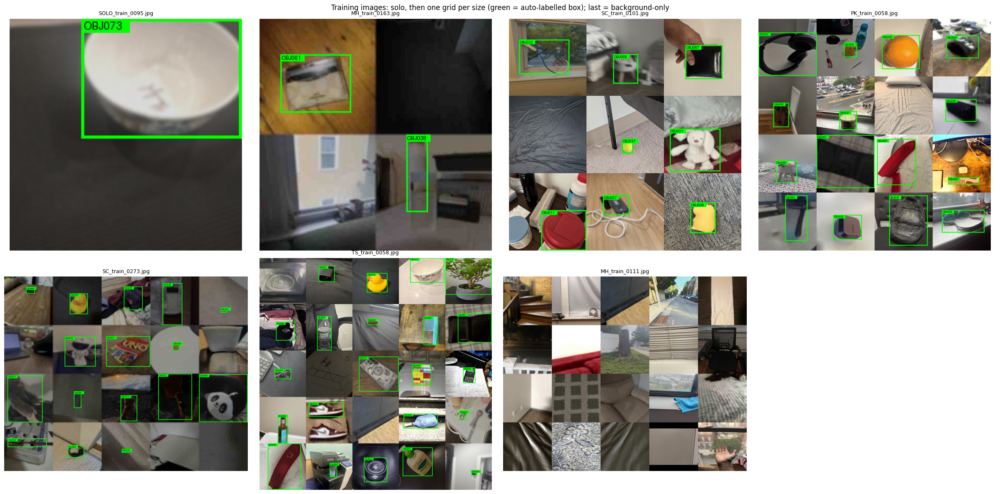

In [20]:
# Visual check: grids with their ground-truth boxes
def read_labels(lbl_path, W, H):
    out = []
    if Path(lbl_path).exists():
        for line in Path(lbl_path).read_text().split("\n"):
            if line.strip():
                c, xc, yc, w, h = line.split(); c = int(c); xc, yc, w, h = map(float, (xc, yc, w, h))
                out.append((c, (xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H))
    return out

def gt_for(split, name):
    with Image.open(YOLO_DIR / "images" / split / name) as im: W, H = im.size
    return read_labels(YOLO_DIR / "labels" / split / name.replace(".jpg", ".txt"), W, H)

def draw_boxes(im, boxes, color="lime", conf=None):
    im = im.copy(); d = ImageDraw.Draw(im)
    for i, (c, x1, y1, x2, y2) in enumerate(boxes):
        d.rectangle([x1, y1, x2, y2], outline=color, width=3)
        txt = CLASSES[c] + (f" {conf[i]:.2f}" if conf is not None else "")
        d.rectangle([x1, y1, x1 + 7 * len(txt) + 4, y1 + 13], fill=color); d.text((x1 + 2, y1 + 1), txt, fill="black")
    return im

def show_grid(names, split, title, fname, n_cols=3):
    n_rows = math.ceil(len(names) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 6 * n_rows))
    for ax, n in zip(np.ravel(axes), names):
        ax.imshow(draw_boxes(Image.open(YOLO_DIR / "images" / split / n), gt_for(split, n)))
        ax.set_title(n, fontsize=9)
    for ax in np.ravel(axes): ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=110); plt.show()

ex = manifest[manifest.split == "train"]
pick = []
for g in ["1x1", "2x2", "3x3", "4x4", "5x4", "5x5"]:
    pool = ex[(ex.kind == "pos") & (ex.grid == g)]
    if len(pool): pick.append(pool.sample(1, random_state=SEED).image.iloc[0])
pick += list(ex[ex.kind == "neg"].sample(min(1, (ex.kind == "neg").sum()), random_state=SEED).image)
show_grid(pick, "train", "Training images: solo, then one grid per size (green = auto-labelled box); last = background-only", "grid_examples.png", n_cols=4)

Boxes checked: 18997
Box size relative to its 224 x 224 photo: median width 0.44, median height 0.44, median area 0.20
Boxes covering (almost) the whole photo: 1.1%  (these are objects that fill the frame, e.g. close-ups)
Boxes that stay inside their own grid cell: 100.0%


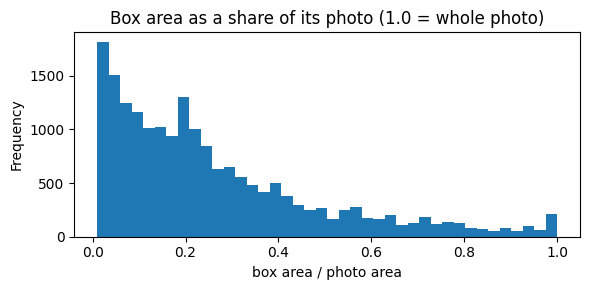

In [21]:
# Automatic check: boxes outline the OBJECT, not the whole photo / cell
rows = []
for split in SPLITS:
    for n in manifest.loc[manifest.split == split, "image"]:
        for c, x1, y1, x2, y2 in gt_for(split, n):
            col, row = int(((x1 + x2) / 2) // IMG_SIZE), int(((y1 + y2) / 2) // IMG_SIZE)   # cell of the box centre
            inside = (x1 >= col * IMG_SIZE - 1 and x2 <= (col + 1) * IMG_SIZE + 1 and
                      y1 >= row * IMG_SIZE - 1 and y2 <= (row + 1) * IMG_SIZE + 1)
            rows.append({"split": split, "w": (x2 - x1) / IMG_SIZE, "h": (y2 - y1) / IMG_SIZE, "inside_cell": inside})
bx = pd.DataFrame(rows); bx["area"] = bx.w * bx.h
whole = (bx.w >= 0.98) & (bx.h >= 0.98)
print(f"Boxes checked: {len(bx)}")
print(f"Box size relative to its 224 x 224 photo: median width {bx.w.median():.2f}, median height {bx.h.median():.2f}, "
      f"median area {bx.area.median():.2f}")
print(f"Boxes covering (almost) the whole photo: {whole.mean():.1%}  (these are objects that fill the frame, e.g. close-ups)")
print(f"Boxes that stay inside their own grid cell: {bx.inside_cell.mean():.1%}")
assert bx.inside_cell.all(), "a box crosses into another cell: check the labels"
assert whole.mean() < 0.25, "too many whole-photo boxes: the labels are not object boxes"
bx.area.plot.hist(bins=40, figsize=(6, 3), title="Box area as a share of its photo (1.0 = whole photo)")
plt.xlabel("box area / photo area"); plt.tight_layout(); plt.savefig(FIG_DIR / "box_size_check.png", dpi=130); plt.show()

## 7. Model: YOLOE-26s pretrained, fine-tuned as a detector
**YOLOE-26s** (small). Following the Ultralytics recipe for training a YOLOE *detector*, the model is built from its detection architecture (`yoloe-26s.yaml`), loaded with the released pretrained weights (`yoloe-26s-seg.pt`), and fine-tuned with `YOLOEPETrainer`, which fuses our 72 object names into the head first (the default trainer would ignore the class names).

| ID | Model | Pretrained weights | Size (detection) | Batch |
|---|---|---|---|---|
| B | YOLOE-26s | `yoloe-26s-seg.pt` | ~11 M parameters | 8 |

YOLOE-26 needs `ultralytics` 8.4.0 or newer; the first run downloads a text encoder (`mobileclip2_b.ts`, ~254 MB).

| Setting | Value | Why |
|---|---|---|
| Input size | **1120** | instructor tip: close to the largest grid, so objects in 5 × 5 grids are not shrunk |
| Batch | 8 (4 for m) | instructor tip for Colab; Ultralytics accumulates gradients to a nominal batch of 64, so all models learn with the same effective batch |
| Epochs | up to 60, early stopping after 15 without improvement | ~200 steps per epoch, so up to ~12,000 steps |
| Optimizer / LR | `auto` (MuSGD or AdamW), cosine schedule | |
| Seed | 42, deterministic | reproducible |

**YOLO training-time augmentation:** horizontal flip 0.5, scale 0.3 (random zoom ± 30 %), translate 0.1, HSV colour (hue 0.015, saturation 0.7, value 0.4). **Mosaic is off**: our images are already grids of up to 25 photos, and mosaic would shrink them further. Rotation and MixUp are off (rotation loosens boxes; MixUp blends objects). Checkpoints are written to Drive every epoch; a disconnected run resumes from `last.pt`.

In [22]:
from ultralytics import YOLO, YOLOE
from ultralytics.models.yolo.yoloe import YOLOEPETrainer
import torch

def load_trained(path):
    # a fine-tuned YOLOE detector; its object names are already fused into the head
    try:
        return YOLOE(str(path))
    except Exception:
        return YOLO(str(path))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (training will be very slow)")

TRAIN_ARGS = dict(
    data=str(DATA_YAML), imgsz=IMGSZ, epochs=2 if QUICK_TEST else EPOCHS, patience=PATIENCE, optimizer="auto",
    seed=SEED, deterministic=True, cos_lr=True, close_mosaic=0,
    mosaic=0.0, mixup=0.0, degrees=0.0, fliplr=0.5, scale=0.3, translate=0.1,
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    workers=N_WORKERS, amp=True, plots=True, verbose=False,
)

def train_model(name):
    run_dir = RUNS_DIR / name
    best, last, done = run_dir / "weights" / "best.pt", run_dir / "weights" / "last.pt", run_dir / "DONE"
    if done.exists() and best.exists():
        print(f"{name}: already trained, skipping"); return best
    t0 = time.time()
    if last.exists():
        print(f"{name}: resuming from {last}"); YOLOE(str(last)).train(resume=True, trainer=YOLOEPETrainer)
    else:
        arch, weights = MODELS[name]
        print(f"{name}: fine-tuning YOLOE from {weights}")
        model = YOLOE(arch).load(weights)                    # detection head, YOLOE-26 pretrained weights
        model.train(project=str(RUNS_DIR), name=name, exist_ok=True, batch=BATCH[name],
                    trainer=YOLOEPETrainer, **TRAIN_ARGS)    # <- fuses the object names into the head
    done.write_text(json.dumps({"finished": time.ctime(), "minutes_this_session": round((time.time() - t0) / 60, 1)}))
    return best

GPU: Tesla T4


## 8. Train
About 2 hours on a T4. If Colab disconnects, run the notebook from the top again: training resumes from the last saved epoch.

In [23]:
ONE_MODEL_PER_SESSION = True
ALL_MODELS = list(MODELS)

def is_done(name):
    return (RUNS_DIR / name / "DONE").exists() and (RUNS_DIR / name / "weights" / "best.pt").exists()

BEST, trained_now = {}, 0
for name in ALL_MODELS:
    if is_done(name):
        print(f"{name}: already trained, skipping"); BEST[name] = RUNS_DIR / name / "weights" / "best.pt"; continue
    if ONE_MODEL_PER_SESSION and trained_now == 1:
        print(f"{name}: not trained yet -> run this cell again in the next session"); continue
    BEST[name] = train_model(name)
    trained_now += 1
    torch.cuda.empty_cache()

RUN_MODELS = [n for n in ALL_MODELS if n in BEST]          # later cells use only finished models
print("\nFinished models:", RUN_MODELS)
print("All models trained: run the rest of the notebook." if len(RUN_MODELS) == len(ALL_MODELS)
      else "Not all models are trained yet: reconnect in a new session and run from the top again "
           "(or run the rest now for results of the finished models).")

B_YOLOE26s: resuming from /content/drive/MyDrive/IE7615_M2_final/runs/B_YOLOE26s/weights/last.pt
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/m2_work/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1120, iou=0.7, kobj=1.0, line_width=None, lr0=0.000132, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive

## 9. Evaluation
**Detection metrics** (Ultralytics `val`): **precision, recall, mAP@0.5** (the metrics the instructor asks for) and mAP@0.5:0.95, per-class AP, confusion matrix, speed.

**Task-level metrics** (requirement 3), at a confidence threshold chosen **on validation**: fully-correct images (every object found with the right ID at IoU ≥ 0.5 and nothing extra), ID-set accuracy, count accuracy, object recall, ID accuracy of found objects, background false-positive rate. After prediction, at most **one box per Object ID** is kept (each ID is one physical object).

**Robustness:** validation and test images re-rendered as *low quality* (4× downscale, brightness × 0.6, JPEG 20), *small objects* (whole image shrunk to half size on a blurred copy; boxes adjusted) and *blurred* (defocus blur).

In [24]:
# Robustness copies of val and test (deterministic, identical for all models)
def perturb_lowq(im):
    w, h = im.size
    im = im.resize((w // 4, h // 4), Image.BILINEAR).resize((w, h), Image.BILINEAR)
    return jpeg(ImageEnhance.Brightness(im).enhance(0.6), 20)

def perturb_small(im):
    w, h = im.size
    bgc = im.resize((w // 8, h // 8), Image.BILINEAR).resize((w, h), Image.BILINEAR).filter(ImageFilter.GaussianBlur(8))
    bgc.paste(im.resize((w // 2, h // 2), Image.BILINEAR), (w // 4, h // 4)); return bgc

def small_labels(txt):
    out = []
    for line in txt.split("\n"):
        if line.strip():
            c, xc, yc, bw, bh = line.split()
            out.append(f"{c} {0.25 + 0.5 * float(xc):.6f} {0.25 + 0.5 * float(yc):.6f} {0.5 * float(bw):.6f} {0.5 * float(bh):.6f}")
    return "\n".join(out) + ("\n" if out else "")

def perturb_blur(im):
    return defocus_blur(im.filter(ImageFilter.GaussianBlur(1.0)), 3)          # out-of-focus photo

PERTURB = {"lowq": (perturb_lowq, lambda t: t), "small": (perturb_small, small_labels), "blur": (perturb_blur, lambda t: t)}
YAMLS = {}
for split in ["val", "test"]:
    for pname, (fimg, flbl) in PERTURB.items():
        tag = f"{split}_{pname}"
        di, dl = YOLO_DIR / "images" / tag, YOLO_DIR / "labels" / tag
        if not di.exists():
            di.mkdir(parents=True); dl.mkdir(parents=True)
            for p in sorted((YOLO_DIR / "images" / split).glob("*.jpg")):
                fimg(Image.open(p).convert("RGB")).save(di / p.name, quality=95)
                (dl / (p.stem + ".txt")).write_text(flbl((YOLO_DIR / "labels" / split / (p.stem + ".txt")).read_text()))
        y = YOLO_DIR / f"data_{tag}.yaml"
        y.write_text(DATA_YAML.read_text().replace("val: images/val", f"val: images/{tag}"))
        YAMLS[tag] = y
print("Robustness sets:", list(YAMLS))

Robustness sets: ['val_lowq', 'val_small', 'val_blur', 'test_lowq', 'test_small', 'test_blur']


In [25]:
def ultra_val(name, data_yaml, split, tag):
    m = load_trained(BEST[name]).val(data=str(data_yaml), split=split, imgsz=IMGSZ, batch=4, conf=0.001, iou=0.6,
                                 project=str(EVAL_DIR), name=f"{name}_{tag}", exist_ok=True, plots=True, verbose=False)
    ap50 = np.full(NUM_CLASSES, np.nan)
    idx = getattr(m.box, "ap_class_index", None)
    if idx is None: idx = m.ap_class_index
    ap50[np.array(idx, int)] = m.box.ap50
    return {"P": m.box.mp, "R": m.box.mr, "mAP50": m.box.map50, "mAP50_95": m.box.map,
            "ms_per_img": m.speed["inference"], "ap50_per_class": ap50}

VAL, TEST, ROB = {}, {}, {}
for name in RUN_MODELS:
    VAL[name]  = ultra_val(name, DATA_YAML, "val", "val")
    TEST[name] = ultra_val(name, DATA_YAML, "test", "test")     # reported only, never used for a decision
    for tag, y in YAMLS.items():
        ROB[(name, tag)] = ultra_val(name, y, "val", tag)["mAP50"]
    print(f"{name}: val mAP50 {VAL[name]['mAP50']:.4f} | test mAP50 {TEST[name]['mAP50']:.4f}")

Validate using the text prompt.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOe-26s summary (fused): 124 layers, 9,493,044 parameters, 0 gradients, 20.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2029.0±1014.1 MB/s, size: 199.9 KB)
val: Scanning /content/m2_work/yolo_dataset/labels/val.cache... 220 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 220/220 65.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 3.9it/s 14.0s
                   all        220       2017      0.948      0.906      0.945      0.884
Speed: 5.8ms preprocess, 41.9ms inference, 0.1ms loss, 3.2ms postprocess per image
Results saved to /content/drive/MyDrive/IE7615_M2_final/eval/B_YOLOE26s_val
Validate using the text prompt.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOe-26s summary (fused): 124 layers, 9,493,044 parameters, 0 gradients, 20

In [26]:
# Predictions cached once per model and split, then scored at any threshold
def predict_split(name, split):
    cache = EVAL_DIR / f"preds_{name}_{split}.pkl"
    if cache.exists(): return pickle.loads(cache.read_bytes())
    model = load_trained(BEST[name]); out = {}
    files = sorted((YOLO_DIR / "images" / split).glob("*.jpg"))
    for i in range(0, len(files), 8):
        for r in model.predict([str(f) for f in files[i:i + 8]], imgsz=IMGSZ, conf=0.05, iou=0.5, verbose=False):
            b = r.boxes
            out[Path(r.path).name] = (b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), b.xyxy.cpu().numpy())
    cache.write_bytes(pickle.dumps(out)); return out

def iou(a, b):
    iw, ih = min(a[2], b[2]) - max(a[0], b[0]), min(a[3], b[3]) - max(a[1], b[1])
    if iw <= 0 or ih <= 0: return 0.0
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

def one_box_per_object(cls, conf, xyxy, iou_thr=DEDUP_IOU):
    # Each Object ID is one physical object and each pasted photo holds one object, so keep at most one box per ID
    # and drop a box that mostly overlaps a more confident box of another ID. A fixed rule, not tuned on test.
    keep, seen = [], set()
    for k in np.argsort(-conf):
        if cls[k] in seen or any(iou(xyxy[k], xyxy[j]) > iou_thr for j in keep): continue
        keep.append(k); seen.add(cls[k])
    keep = np.array(keep, int)
    return cls[keep], conf[keep], xyxy[keep]

def score_image(gt, pred, thr, iou_thr=0.5, dedup=True):
    cls, conf, xyxy = pred; keep = conf >= thr
    cls, conf, xyxy = cls[keep], conf[keep], xyxy[keep]
    if dedup and len(cls): cls, conf, xyxy = one_box_per_object(cls, conf, xyxy)
    order = np.argsort(-conf); used = set(); tp = 0
    for k in order:                                                   # greedy class-aware matching
        best_j, best_iou = None, iou_thr
        for j, g in enumerate(gt):
            if j not in used and g[0] == cls[k]:
                v = iou(g[1:], xyxy[k])
                if v >= best_iou: best_j, best_iou = j, v
        if best_j is not None: used.add(best_j); tp += 1
    found = correct = 0                                               # class-agnostic: was each object found, with the right ID?
    for g in gt:
        ious = [iou(g[1:], xyxy[k]) for k in range(len(cls))]
        if ious and max(ious) >= iou_thr:
            found += 1; correct += int(cls[int(np.argmax(ious))] == g[0])
    return {"strict": int(tp == len(gt) and len(cls) == len(gt)),
            "idset": int(set(cls.tolist()) == {g[0] for g in gt}),
            "count": int(len(cls) == len(gt)), "n_gt": len(gt), "found": found, "id_correct": correct,
            "is_bg": int(len(gt) == 0), "bg_fp": int(len(gt) == 0 and len(cls) > 0)}

def task_metrics(name, split, thr, dedup=True):
    preds = predict_split(name, split)
    rows = [dict(image=n, **score_image(gt_for(split, n), p, thr, dedup=dedup))
            for n, p in preds.items()]
    d = pd.DataFrame(rows)
    return d, {"fully_correct": d.strict.mean(), "fully_correct_multi": d[d.is_bg == 0].strict.mean(), "idset_acc": d.idset.mean(), "count_acc": d["count"].mean(),
               "object_recall": d.found.sum() / d.n_gt.sum(), "id_acc_found": d.id_correct.sum() / max(1, d.found.sum()),
               "bg_fp_rate": d.bg_fp.sum() / max(1, d.is_bg.sum())}

THRESH = np.round(np.arange(0.10, 0.91, 0.05), 2)
THR = {}
for name in RUN_MODELS:
    sweep = [task_metrics(name, "val", t)[1]["fully_correct"] for t in THRESH]
    THR[name] = float(THRESH[int(np.argmax(sweep))])
    print(f"{name}: confidence threshold chosen on val = {THR[name]:.2f} (val fully-correct {max(sweep):.3f})")

B_YOLOE26s: confidence threshold chosen on val = 0.15 (val fully-correct 0.441)


In [27]:
def bootstrap_ci(x, n=2000, seed=SEED):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    m = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return np.percentile(m, 2.5), np.percentile(m, 97.5)

rows, TEST_ROWS = [], {}
for name in RUN_MODELS:
    dval, mval = task_metrics(name, "val", THR[name])
    dte,  mte  = task_metrics(name, "test", THR[name]); TEST_ROWS[name] = dte
    _, mraw = task_metrics(name, "test", THR[name], dedup=False)          # same threshold, without the one-box-per-ID rule
    lo, hi = bootstrap_ci(dte[dte.is_bg == 0].strict)                    # CI of the multi-object rate
    params = sum(p.numel() for p in load_trained(BEST[name]).model.parameters()) / 1e6
    rows.append({"model": name, "params_M": round(params, 2), "thr": THR[name],
                 "val_mAP50": VAL[name]["mAP50"], "val_mAP50_95": VAL[name]["mAP50_95"], "val_fully_correct": mval["fully_correct"],
                 "test_P": TEST[name]["P"], "test_R": TEST[name]["R"],
                 "test_mAP50": TEST[name]["mAP50"], "test_mAP50_95": TEST[name]["mAP50_95"],
                 "test_fully_correct": mte["fully_correct"], "test_fully_correct_multi": mte["fully_correct_multi"],
                 "fully_correct_multi_CI": f"{lo:.3f}-{hi:.3f}", "test_fully_correct_multi_no_dedup": mraw["fully_correct_multi"],
                 "test_idset_acc": mte["idset_acc"], "test_count_acc": mte["count_acc"],
                 "test_object_recall": mte["object_recall"], "test_id_acc_found": mte["id_acc_found"],
                 "test_bg_fp_rate": mte["bg_fp_rate"], "ms_per_img": TEST[name]["ms_per_img"],
                 **{f"rob_{t}": ROB[(name, t)] for t in YAMLS}})
RESULTS = pd.DataFrame(rows).set_index("model")
RESULTS.to_csv(SAVE_DIR / "results_m2.csv")
pd.set_option("display.width", 250); print(RESULTS.round(4).T.to_string())

model                               B_YOLOE26s
params_M                                  10.0
thr                                       0.15
val_mAP50                               0.9447
val_mAP50_95                            0.8837
val_fully_correct                       0.4409
test_P                                  0.9199
test_R                                  0.9241
test_mAP50                              0.9474
test_mAP50_95                           0.8963
test_fully_correct                      0.4727
test_fully_correct_multi                0.4527
fully_correct_multi_CI             0.388-0.522
test_fully_correct_multi_no_dedup       0.4328
test_idset_acc                          0.5273
test_count_acc                          0.5818
test_object_recall                      0.9182
test_id_acc_found                       0.9915
test_bg_fp_rate                         0.3158
ms_per_img                             41.6112
rob_val_lowq                            0.8378
rob_val_small

## 10. Final model
Only YOLOE-26s is trained, so it is the final model. The cell below confirms it, saves its weights path and confidence threshold (chosen on validation), and plots its size and speed for the report.

            val_mAP50  params_M  val_robust_mean  within_0.01
model                                                        
B_YOLOE26s     0.9447      10.0           0.8667         True

Selected model: B_YOLOE26s | threshold (chosen on val): 0.15


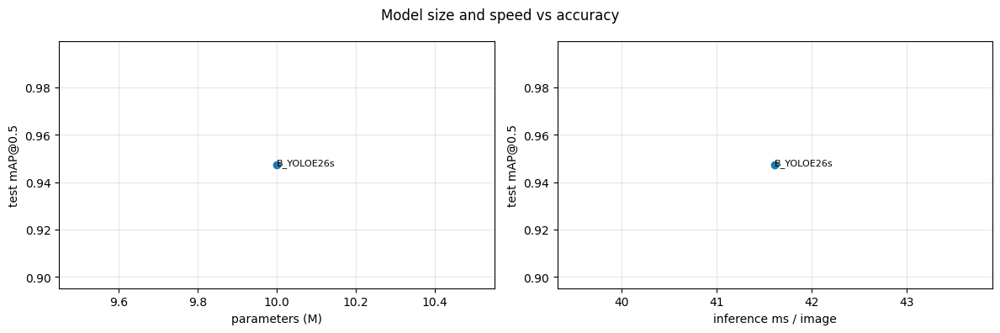

In [28]:
sel = RESULTS[["val_mAP50", "params_M"]].copy()
sel["val_robust_mean"] = [np.mean([ROB[(n, t)] for t in YAMLS if t.startswith("val")]) for n in sel.index]
best_val = sel.val_mAP50.max()
sel["within_0.01"] = sel.val_mAP50 >= best_val - 0.01
cand = sel[sel["within_0.01"]].sort_values(["val_robust_mean", "params_M"], ascending=[False, True])
SELECTED = cand.index[0]
sel.round(4).to_csv(SAVE_DIR / "model_selection.csv")
print(sel.round(4).to_string()); print("\nSelected model:", SELECTED, "| threshold (chosen on val):", THR[SELECTED])
Path(SAVE_DIR, "selected_model.txt").write_text(f"{SELECTED}\n{BEST[SELECTED]}\nthreshold {THR[SELECTED]}")

# Size vs accuracy vs speed (for the report)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(RESULTS.params_M, RESULTS.test_mAP50)
ax[1].scatter(RESULTS.ms_per_img, RESULTS.test_mAP50)
for n in RESULTS.index:
    ax[0].annotate(n, (RESULTS.params_M[n], RESULTS.test_mAP50[n]), fontsize=8)
    ax[1].annotate(n, (RESULTS.ms_per_img[n], RESULTS.test_mAP50[n]), fontsize=8)
ax[0].set_xlabel("parameters (M)"); ax[1].set_xlabel("inference ms / image")
for a in ax: a.set_ylabel("test mAP@0.5"); a.grid(alpha=0.3)
plt.suptitle("Model size and speed vs accuracy"); plt.tight_layout(); plt.savefig(FIG_DIR / "size_vs_accuracy.png", dpi=150); plt.show()

Loss terms summed: box_loss, cls_loss, l1_loss


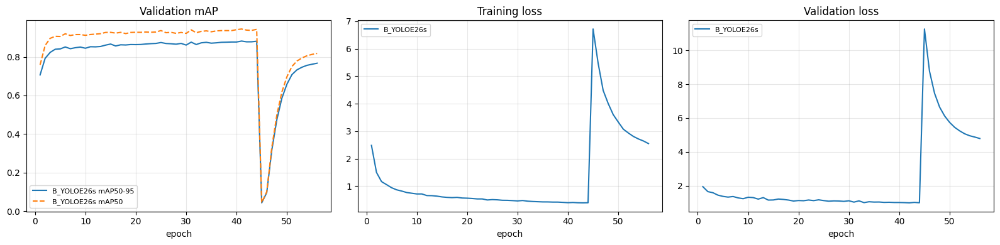

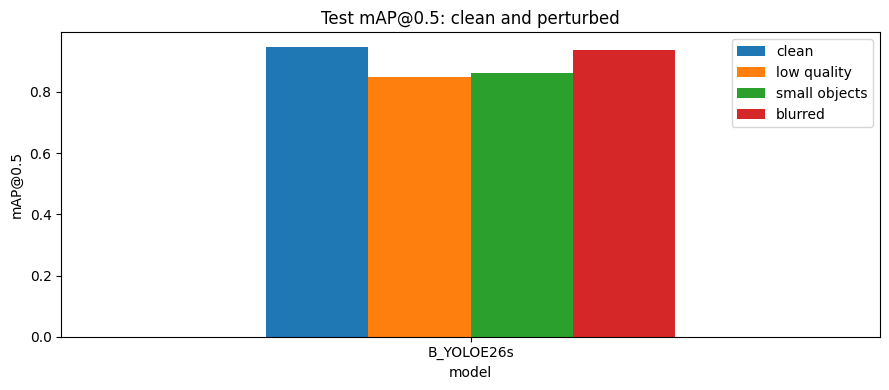

In [29]:
# Training curves (YOLOE-26 has no DFL loss, so the available loss columns are summed)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name in RUN_MODELS:
    r = pd.read_csv(RUNS_DIR / name / "results.csv"); r.columns = [c.strip() for c in r.columns]
    tr_loss = [c for c in r.columns if c.startswith("train/") and c.endswith("loss")]
    va_loss = [c for c in r.columns if c.startswith("val/") and c.endswith("loss")]
    axes[0].plot(r.epoch, r["metrics/mAP50-95(B)"], label=f"{name} mAP50-95")
    axes[0].plot(r.epoch, r["metrics/mAP50(B)"], "--", label=f"{name} mAP50")
    axes[1].plot(r.epoch, r[tr_loss].sum(axis=1), label=name)
    axes[2].plot(r.epoch, r[va_loss].sum(axis=1), label=name)
print("Loss terms summed:", ", ".join(c.split("/")[1] for c in tr_loss))
for ax, t in zip(axes, ["Validation mAP", "Training loss", "Validation loss"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "training_curves.png", dpi=150); plt.show()

# Clean vs perturbed test mAP
cols = ["test_mAP50", "rob_test_lowq", "rob_test_small", "rob_test_blur"]
RESULTS[cols].rename(columns={"test_mAP50": "clean", "rob_test_lowq": "low quality", "rob_test_small": "small objects",
                              "rob_test_blur": "blurred"}).plot.bar(
    figsize=(9, 4), rot=0, title="Test mAP@0.5: clean and perturbed")
plt.ylabel("mAP@0.5"); plt.tight_layout(); plt.savefig(FIG_DIR / "robustness.png", dpi=150); plt.show()

### 10.1 Error analysis of the selected model
Lowest per-class AP, the confusion matrix written by Ultralytics, and the test images that are not fully correct (green = ground truth, red = prediction).

Lowest test AP@0.5 classes:
 OBJ038    0.457
OBJ014    0.519
OBJ063    0.716
OBJ010    0.720
OBJ065    0.734
OBJ057    0.745
OBJ016    0.765
OBJ034    0.782
OBJ061    0.792
OBJ037    0.811


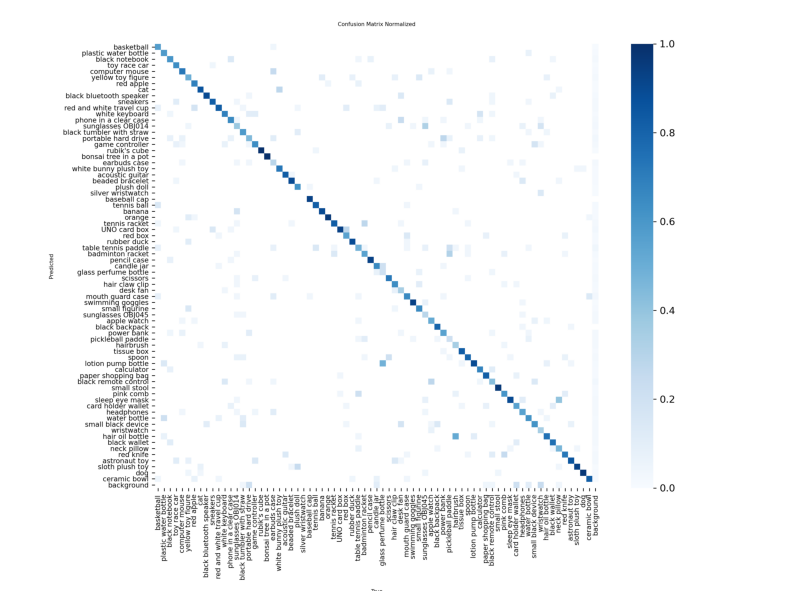

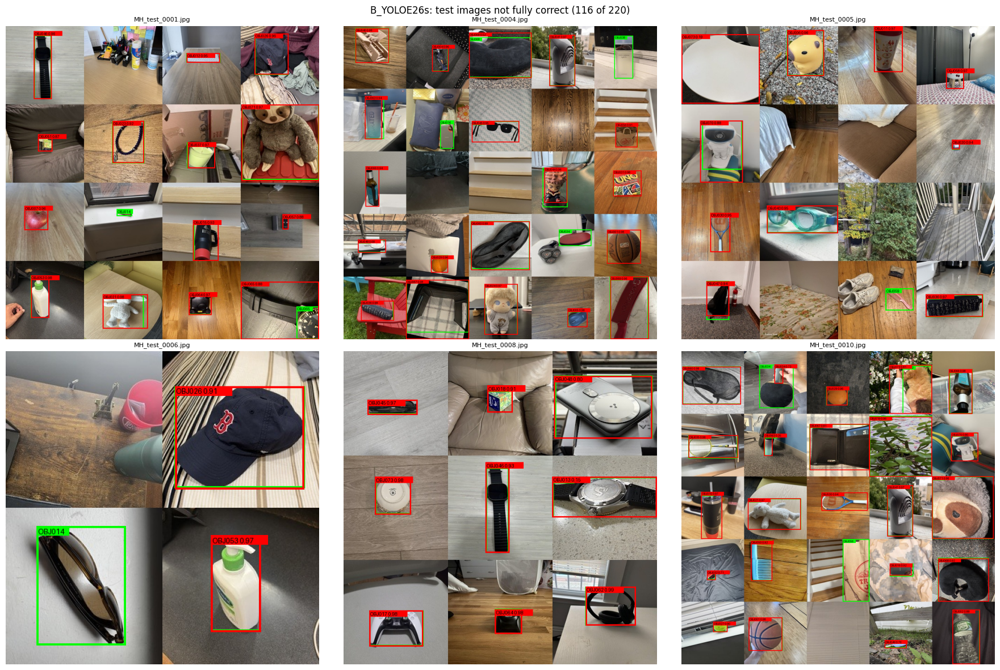

In [30]:
ap = pd.Series(TEST[SELECTED]["ap50_per_class"], index=CLASSES).sort_values()
print("Lowest test AP@0.5 classes:\n", ap.head(10).round(3).to_string())
ap.to_csv(SAVE_DIR / f"per_class_ap50_{SELECTED}.csv")
cm = EVAL_DIR / f"{SELECTED}_test" / "confusion_matrix_normalized.png"
if cm.exists():
    shutil.copy(cm, FIG_DIR / "confusion_matrix_selected.png")
    plt.figure(figsize=(10, 10)); plt.imshow(Image.open(cm)); plt.axis("off"); plt.show()

preds = predict_split(SELECTED, "test")
fails = TEST_ROWS[SELECTED][TEST_ROWS[SELECTED].strict == 0].image.tolist()
fails_df = []
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, n in zip(np.ravel(axes), fails[:6]):
    im = Image.open(YOLO_DIR / "images" / "test" / n).convert("RGB")
    gt = gt_for("test", n)
    c, cf, xy = preds[n]; k = cf >= THR[SELECTED]
    c, cf, xy = one_box_per_object(c[k], cf[k], xy[k]) if k.any() else (c[k], cf[k], xy[k])
    im = draw_boxes(im, gt, "lime")
    im = draw_boxes(im, [(int(a), *b) for a, b in zip(c, xy)], "red", cf)
    ax.imshow(im); ax.set_title(n, fontsize=8)
for ax in np.ravel(axes): ax.axis("off")
plt.suptitle(f"{SELECTED}: test images not fully correct ({len(fails)} of {len(TEST_ROWS[SELECTED])})")
plt.tight_layout(); plt.savefig(FIG_DIR / "failures_selected.png", dpi=130); plt.show()
for n in fails:
    c, cf, xy = preds[n]; k = cf >= THR[SELECTED]
    c, cf, xy = one_box_per_object(c[k], cf[k], xy[k]) if k.any() else (c[k], cf[k], xy[k])
    gt = gt_for("test", n)
    fails_df.append({"image": n, "true_ids": " ".join(sorted(CLASSES[g[0]] for g in gt)),
                     "pred_ids": " ".join(sorted(CLASSES[int(a)] for a in c))})
pd.DataFrame(fails_df).to_csv(SAVE_DIR / "test_failures_selected.csv", index=False)

### 10.2 Background audit with the trained detector
A background photo that the detector confidently labels as an object either shows a registered object (then it should not be a negative) or is a real false positive. Photos are checked at 448 px (the size of one cell in a 2 × 2 grid at `imgsz=1120`). To drop a photo, add its file name to `EXCLUDE_BG`, set `REGENERATE = True` and rerun from §2.

1 of 371 background photos get a detection with confidence >= 0.5
split              file pred_id     conf
 test OBJ042_bg_001.jpg  OBJ027 0.563286


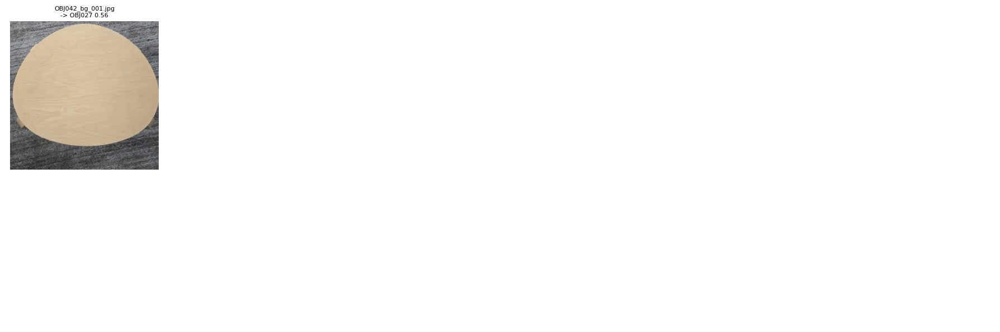

In [31]:
AUDIT_CONF = 0.5
all_bg = [(s, p) for s in SPLITS for p in BG[s]]
audit_model, flag = load_trained(BEST[SELECTED]), []
for i in range(0, len(all_bg), 32):
    chunk = all_bg[i:i + 32]
    results = audit_model.predict([load_photo(p) for _, p in chunk], imgsz=448, conf=AUDIT_CONF, verbose=False)
    for (s, p), r in zip(chunk, results):
        if len(r.boxes):
            k = int(r.boxes.conf.argmax())
            flag.append({"split": s, "file": Path(p).name, "pred_id": CLASSES[int(r.boxes.cls[k])],
                         "conf": float(r.boxes.conf[k]), "path": p})
flag = pd.DataFrame(flag, columns=["split", "file", "pred_id", "conf", "path"]).sort_values("conf", ascending=False)
flag.drop(columns="path").to_csv(SAVE_DIR / "background_audit.csv", index=False)
print(f"{len(flag)} of {len(all_bg)} background photos get a detection with confidence >= {AUDIT_CONF}")
print(flag.drop(columns="path").head(20).to_string(index=False))
if len(flag):
    fig, axes = plt.subplots(2, 6, figsize=(18, 6))
    for ax, row in zip(np.ravel(axes), flag.itertuples()):
        ax.imshow(load_photo(row.path)); ax.set_title(f"{row.file}\n-> {row.pred_id} {row.conf:.2f}", fontsize=8)
    for ax in np.ravel(axes): ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "background_audit.png", dpi=130); plt.show()

### 10.3 Metrics per image type (selected model, test set)
mAP@0.5, precision and recall separately for solo images and each grid size, so it is visible whether large grids (small objects) are harder.

In [32]:
per_type = []
for g in ["1x1", "2x2", "3x3", "4x4", "5x4", "5x5"]:
    names_g = manifest[(manifest.split == "test") & (manifest.grid == g)].image.tolist()
    if not names_g: continue
    tag = f"test_type_{g}"
    di, dl = YOLO_DIR / "images" / tag, YOLO_DIR / "labels" / tag
    if not di.exists():
        di.mkdir(parents=True); dl.mkdir(parents=True)
        for n in names_g:
            shutil.copy(YOLO_DIR / "images" / "test" / n, di / n)
            shutil.copy(YOLO_DIR / "labels" / "test" / n.replace(".jpg", ".txt"), dl / n.replace(".jpg", ".txt"))
    y = YOLO_DIR / f"data_{tag}.yaml"; y.write_text(DATA_YAML.read_text().replace("val: images/val", f"val: images/{tag}"))
    m = ultra_val(SELECTED, y, "val", tag)
    per_type.append({"image type": "solo" if g == "1x1" else f"grid {g}", "images": len(names_g),
                     "objects": int(manifest[(manifest.split == "test") & (manifest.grid == g)].n_objects.sum()),
                     "precision": m["P"], "recall": m["R"], "mAP@0.5": m["mAP50"], "mAP@0.5:0.95": m["mAP50_95"]})
PER_TYPE = pd.DataFrame(per_type); PER_TYPE.to_csv(SAVE_DIR / "metrics_per_image_type.csv", index=False)
print(PER_TYPE.round(3).to_string(index=False))

Validate using the text prompt.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOe-26s summary (fused): 124 layers, 9,493,044 parameters, 0 gradients, 20.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 784.0±260.0 MB/s, size: 16.2 KB)
val: Scanning /content/m2_work/yolo_dataset/labels/test_type_1x1... 60 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 2.2Kit/s 0.0s
val: New cache created: /content/m2_work/yolo_dataset/labels/test_type_1x1.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.1it/s 3.7s
                   all         60         53      0.666      0.789      0.826      0.672
Speed: 6.3ms preprocess, 41.2ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/drive/MyDrive/IE7615_M2_final/eval/B_YOLOE26s_test_type_1x1
Validate using the text prompt.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 

### 10.4 Label check: where the model disagrees with an auto-labelled box
On the **validation** single photos, a confident prediction of the right Object ID whose box overlaps the label box by less than 50 % often means the **label** is wrong, not the model. Red = label box, green = model box. Bad labels found here can be added to `MANUAL_DROP` for a final run.

5 of 568 validation photos: confident prediction, but box disagrees with the label (IoU < 0.5)


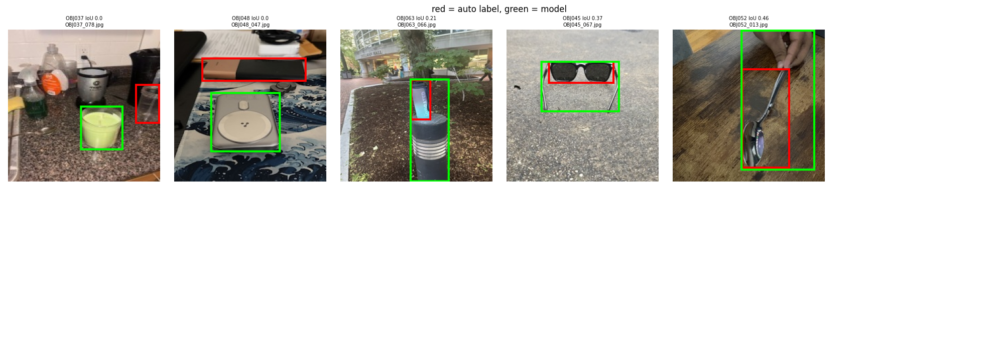

In [33]:
val_photos = SINGLE["val"]
check_model, sus = load_trained(BEST[SELECTED]), []
for i in range(0, len(val_photos), 16):
    chunk = val_photos.iloc[i:i + 16]
    res = check_model.predict([load_photo(p) for p in chunk.path], imgsz=448, conf=0.5, verbose=False)
    for (_, r), pr in zip(chunk.iterrows(), res):
        same = [(float(cf), b) for cf, b, k in zip(pr.boxes.conf, pr.boxes.xyxy.tolist(), pr.boxes.cls) if int(k) == r.cls]
        if same:
            cf, b = max(same)
            o = box_iou(b, BOXES[r.path])
            if o < 0.5: sus.append({"object_id": r.label, "file": r.fname, "path": r.path, "model_conf": round(cf, 2),
                                    "iou": round(o, 2), "model_box": b})
sus = pd.DataFrame(sus, columns=["object_id", "file", "path", "model_conf", "iou", "model_box"]).sort_values("iou")
sus.drop(columns="model_box").to_csv(SAVE_DIR / "suspicious_labels.csv", index=False)
print(f"{len(sus)} of {len(val_photos)} validation photos: confident prediction, but box disagrees with the label (IoU < 0.5)")
if len(sus):
    fig, axes = plt.subplots(2, 6, figsize=(20, 7))
    for ax, (_, r) in zip(axes.flat, sus.head(12).iterrows()):
        im = load_photo(r.path); d = ImageDraw.Draw(im)
        d.rectangle(BOXES[r.path], outline="red", width=3); d.rectangle(r.model_box, outline="lime", width=3)
        ax.imshow(im); ax.set_title(f"{r.object_id} IoU {r.iou}\n{r.file}", fontsize=7)
    for ax in axes.flat: ax.axis("off")
    plt.suptitle("red = auto label, green = model"); plt.tight_layout(); plt.savefig(FIG_DIR / "label_check.png", dpi=130); plt.show()

### 10.5 Photos left out for having no reliable box
These photos were **never used** (not in any split). How often does the selected model still find the photo's own Object ID?

In [34]:
left = lab[~lab.status.isin(KEEP)]
found = []
for i in range(0, len(left), 16):
    chunk = left.iloc[i:i + 16]
    res = check_model.predict([load_photo(p) for p in chunk.path], imgsz=448, conf=THR[SELECTED], verbose=False)
    for (_, r), pr in zip(chunk.iterrows(), res):
        found.append({"label": r.label, "status": r.status,
                      "found": r.label in {CLASSES[int(k)] for k in pr.boxes.cls}})
found = pd.DataFrame(found, columns=["label", "status", "found"])
LEFT_FOUND = found.found.mean() if len(found) else float("nan")
print(f"Left-out photos where the model finds the right Object ID: {found.found.sum()}/{len(found)} ({LEFT_FOUND:.0%})")
print(found.groupby("status").found.agg(["size", "mean"]).round(2).to_string())
found.to_csv(SAVE_DIR / "left_out_photos_found.csv", index=False)

Left-out photos where the model finds the right Object ID: 1614/3054 (53%)
                size  mean
status                    
disagree         462  0.77
no_detection     903  0.30
one_model_only  1627  0.58
too_small         62  0.71


## 11. Inference: IDs and locations of all objects in an image (requirement 3)
`detect_objects(path)` returns one row per detected object: **Object ID, object name, confidence and box** (pixel coordinates `x1, y1` top-left, `x2, y2` bottom-right), and draws the boxes. Demonstrated on unseen test grids of each size, and on any of your own photos placed in `SAVE_DIR/demo_photos/`.

SOLO_test_0034.jpg | true IDs: OBJ070


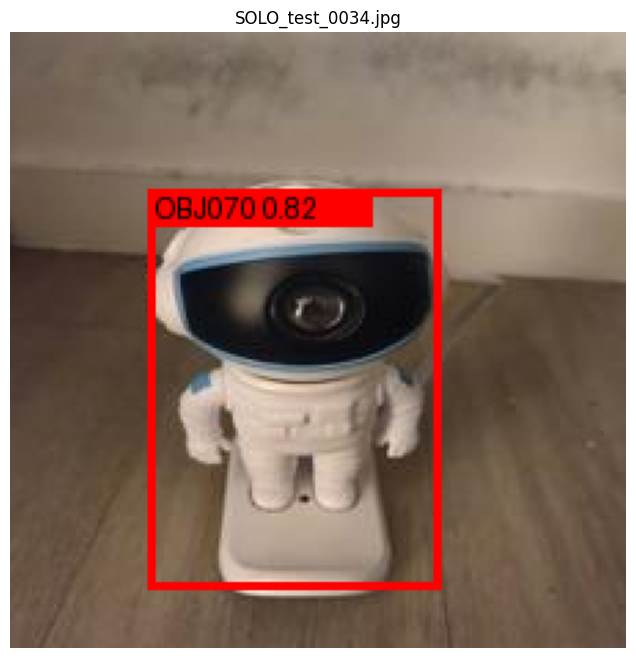

object_id          name  confidence        x1        y1         x2         y2
   OBJ070 astronaut toy       0.821 50.599998 57.099998 156.800003 202.100006 

PK_test_0011.jpg | true IDs: OBJ070 OBJ022 OBJ041 OBJ039


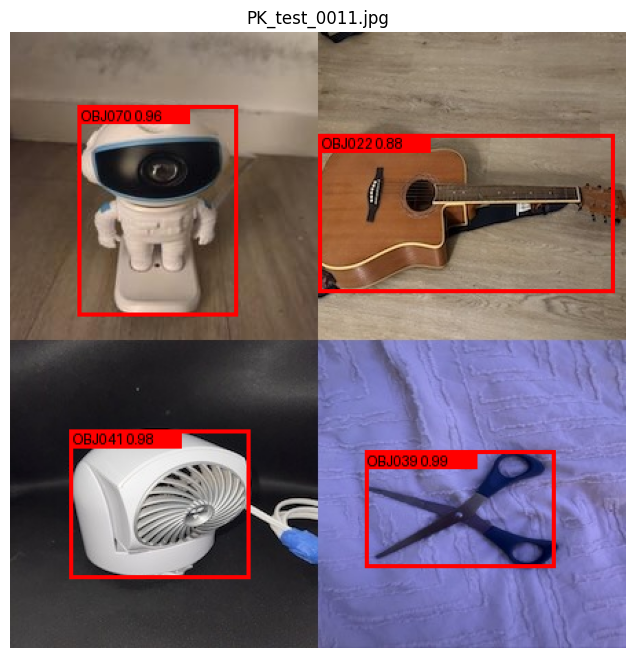

object_id            name  confidence         x1         y1         x2         y2
   OBJ039        scissors       0.987 258.299988 304.899994 396.600006 389.600006
   OBJ041        desk fan       0.975  43.799999 289.000000 174.600006 397.799988
   OBJ070   astronaut toy       0.956  49.799999  53.599998 165.399994 206.600006
   OBJ022 acoustic guitar       0.885 224.600006  74.000000 439.000000 189.500000 

SC_test_0037.jpg | true IDs: OBJ022 OBJ023 OBJ072 OBJ005 OBJ010 OBJ039 OBJ051 OBJ046


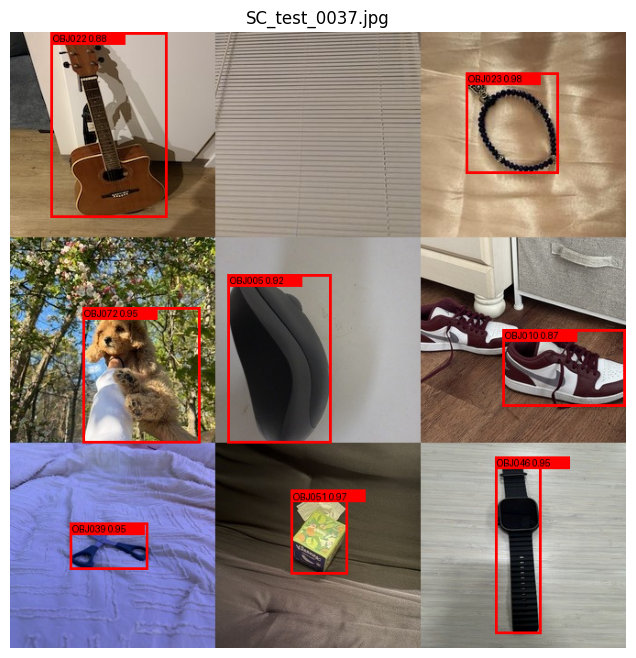

object_id            name  confidence         x1         y1         x2         y2
   OBJ023 beaded bracelet       0.975 497.600006  44.200001 598.599976 154.300003
   OBJ051      tissue box       0.969 306.799988 499.799988 368.200012 591.200012
   OBJ039        scissors       0.953  65.800003 535.500000 150.899994 586.099976
   OBJ046     apple watch       0.948 529.000000 463.200012 579.400024 656.500000
   OBJ072             dog       0.948  79.300003 300.200012 207.399994 448.100006
   OBJ005  computer mouse       0.921 237.699997 264.000000 350.200012 448.399994
   OBJ022 acoustic guitar       0.885  44.900002   0.200000 171.100006 202.199997
   OBJ010        sneakers       0.866 537.599976 324.200012 671.799988 408.799988 

PK_test_0013.jpg | true IDs: OBJ014 OBJ019 OBJ036 OBJ060 OBJ035 OBJ042 OBJ021 OBJ050 OBJ005 OBJ031 OBJ018 OBJ048 OBJ034 OBJ073 OBJ052 OBJ071


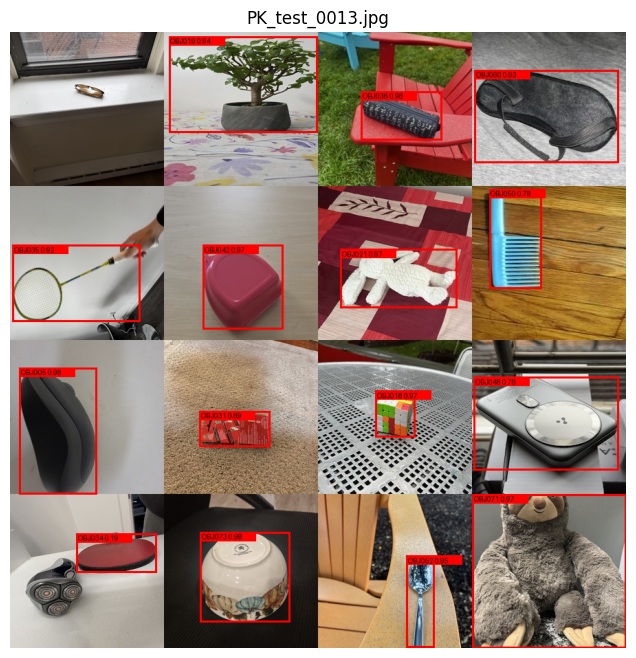

object_id                  name  confidence         x1         y1         x2         y2
   OBJ036           pencil case       0.983 510.500000  86.500000 628.000000 157.399994
   OBJ073          ceramic bowl       0.978 276.799988 727.000000 407.100006 858.799988
   OBJ005        computer mouse       0.975  13.700000 488.000000 126.099998 672.799988
   OBJ018          rubik's cube       0.973 531.500000 521.599976 589.599976 589.900024
   OBJ042      mouth guard case       0.973 280.500000 309.600006 397.799988 432.700012
   OBJ021 white bunny plush toy       0.967 480.600006 315.799988 650.700012 401.600006
   OBJ071       sloth plush toy       0.966 672.500000 672.099976 896.000000 896.000000
   OBJ052                 spoon       0.951 576.599976 761.799988 617.000000 895.799988
   OBJ019  bonsai tree in a pot       0.939 231.300003   6.100000 447.299988 146.899994
   OBJ060        sleep eye mask       0.929 675.799988  55.500000 885.400024 190.199997
   OBJ035      badminton racket 

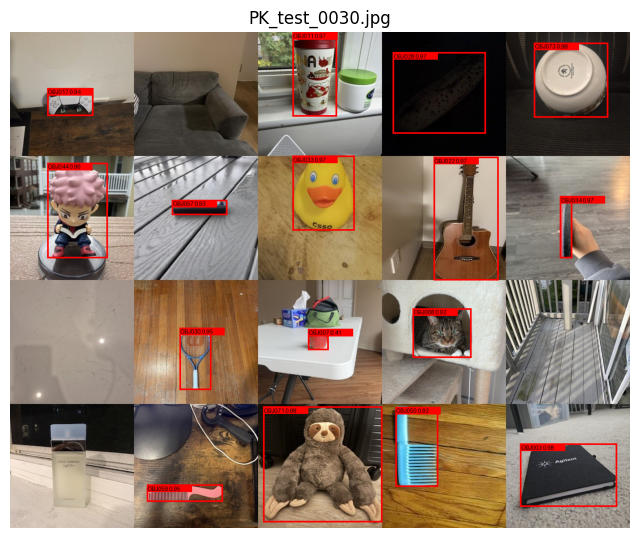

object_id                     name  confidence         x1         y1          x2         y2
   OBJ073             ceramic bowl       0.982 946.799988  19.400000 1080.099976 154.100006
   OBJ071          sloth plush toy       0.979 457.200012 676.900024  672.099976 885.900024
   OBJ003           black notebook       0.976 921.500000 743.700012 1096.300049 857.700012
   OBJ022          acoustic guitar       0.974 765.099976 225.800003  882.299988 448.600006
   OBJ011 red and white travel cup       0.973 510.100006   0.000000  590.000000 152.500000
   OBJ028                   banana       0.973 691.799988  36.599998  859.900024 183.199997
   OBJ033              rubber duck       0.966 510.000000 223.699997  622.000000 358.600006
   OBJ034      table tennis paddle       0.966 993.599976 296.899994 1015.099976 408.500000
   OBJ044           small figurine       0.962  67.000000 236.100006  176.800003 408.600006
   OBJ030            tennis racket       0.952 306.299988 534.299988  363.799988

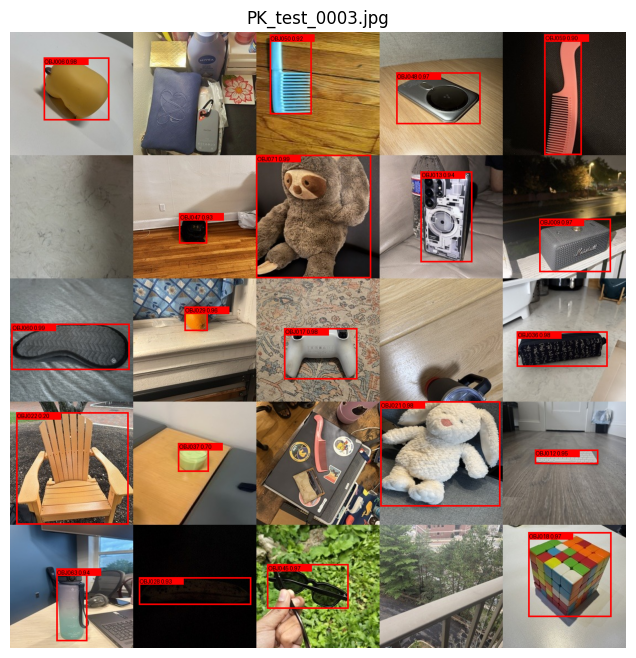

object_id                    name  confidence         x1         y1          x2          y2
   OBJ060          sleep eye mask       0.989   2.700000 530.900024  217.000000  614.200012
   OBJ071         sloth plush toy       0.985 447.600006 223.699997  656.599976  447.799988
   OBJ036             pencil case       0.983 921.799988 544.099976 1086.500000  608.099976
   OBJ021   white bunny plush toy       0.983 673.099976 671.900024  891.900024  862.299988
   OBJ017         game controller       0.981 498.500000 538.400024  631.799988  631.799988
   OBJ006       yellow toy figure       0.975  61.000000  46.599998  180.899994  160.600006
   OBJ018            rubik's cube       0.974 942.000000 909.599976 1093.599976 1063.500000
   OBJ009 black bluetooth speaker       0.973 962.000000 339.500000 1092.099976  436.100006
   OBJ045              sunglasses       0.967 467.600006 967.799988  615.400024 1048.300049
   OBJ048              power bank       0.967 702.000000  73.800003  855.599976 

In [35]:
DETECTOR = load_trained(BEST[SELECTED]); DET_THR = THR[SELECTED]

def detect_objects(path, conf=DET_THR, show=True):
    r = DETECTOR.predict(str(path), imgsz=IMGSZ, conf=conf, iou=0.5, verbose=False)[0]
    b = r.boxes
    cls, cf, xy = b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy(), b.xyxy.cpu().numpy()
    if len(cls): cls, cf, xy = one_box_per_object(cls, cf, xy)
    out = pd.DataFrame({"object_id": [CLASSES[int(c)] for c in cls], "name": [NAMES.get(CLASSES[int(c)], "") for c in cls],
                        "confidence": cf.round(3),
                        **{k: v for k, v in zip(["x1", "y1", "x2", "y2"], xy.round(1).T)}})
    out = out.sort_values("confidence", ascending=False).reset_index(drop=True)
    if show:
        im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
        im = draw_boxes(im, [(CLASSES.index(i), x1, y1, x2, y2) for i, x1, y1, x2, y2 in
                             out[["object_id", "x1", "y1", "x2", "y2"]].itertuples(index=False)], "red", out.confidence.values)
        plt.figure(figsize=(8, 8)); plt.imshow(im); plt.axis("off"); plt.title(Path(path).name)
        plt.savefig(FIG_DIR / f"demo_{Path(path).stem}.png", dpi=110, bbox_inches="tight"); plt.show()
    return out

demo = manifest[(manifest.split == "test") & (manifest.kind == "pos")]
for n in demo.groupby("grid").sample(1, random_state=1).image:
    print(n, "| true IDs:", manifest.set_index("image").loc[n, "ids"])
    print(detect_objects(YOLO_DIR / "images" / "test" / n).to_string(index=False), "\n")

DEMO_DIR = SAVE_DIR / "demo_photos"; DEMO_DIR.mkdir(exist_ok=True)
for p in sorted(DEMO_DIR.glob("*")):
    if p.suffix.lower() in IMG_EXT:
        print(p.name); print(detect_objects(p).to_string(index=False), "\n")

## 12. Results and report information

In [36]:
summary_cols = ["params_M", "val_mAP50", "val_mAP50_95", "test_P", "test_R", "test_mAP50", "test_mAP50_95", "test_fully_correct",
                "test_fully_correct_multi", "fully_correct_multi_CI", "test_fully_correct_multi_no_dedup",
                "test_idset_acc", "test_object_recall", "test_id_acc_found", "test_bg_fp_rate",
                "rob_test_lowq", "rob_test_small", "rob_test_blur", "ms_per_img"]
final = RESULTS[summary_cols].copy()
final.to_csv(SAVE_DIR / "results_summary_m2.csv")

print("=== For the report ===")
print(f"Object IDs used ({len(CLASSES)}):", ", ".join(CLASSES))
print("Excluded:", removed, "| non-224 images resized:", len(not224), "| OBJ004 bg renamed:", len(renames))
print("\nGrid sizes used (cols x rows): images per split\n", pd.crosstab(manifest.grid, manifest.split).to_string())
print(f"\nGrid images: {len(manifest)} ({', '.join(f'{s} {(manifest.split == s).sum()}' for s in SPLITS)}), "
      f"{(manifest.kind == 'neg').sum()} background-only, {int(manifest.n_objects.sum())} labelled objects")
print("\nLabels: YOLO-World + YOLOE auto-labelling, kept when both agree (IoU >= 0.5); photos per outcome:")
print(summary_lab.to_string())
print("Hand-rejected after visual check (MANUAL_DROP):", len(MANUAL_DROP), "| object names from:", name_source)
print(f"Label check: {len(sus)} validation photos with a suspicious box | left-out photos found by the model: {LEFT_FOUND:.0%}")
print("\nSelected model:", SELECTED, "| confidence threshold (chosen on val):", THR[SELECTED])
print("\nPer image type (selected model, test):\n", PER_TYPE.round(3).to_string(index=False))
print("\nTest metrics (precision, recall, mAP@0.5 requested by the instructor):")
print(final[["test_P", "test_R", "test_mAP50", "test_mAP50_95"]].round(4).to_string())
print("\nAll metrics:\n", final.round(4).T.to_string())
print("\nFigures saved in", FIG_DIR, "->", sorted(p.name for p in FIG_DIR.glob("*.png")))

=== For the report ===
Object IDs used (72): OBJ001, OBJ002, OBJ003, OBJ004, OBJ005, OBJ006, OBJ007, OBJ008, OBJ009, OBJ010, OBJ011, OBJ012, OBJ013, OBJ014, OBJ015, OBJ016, OBJ017, OBJ018, OBJ019, OBJ020, OBJ021, OBJ022, OBJ023, OBJ024, OBJ025, OBJ026, OBJ027, OBJ028, OBJ029, OBJ030, OBJ031, OBJ032, OBJ033, OBJ034, OBJ035, OBJ036, OBJ037, OBJ038, OBJ039, OBJ040, OBJ041, OBJ042, OBJ043, OBJ044, OBJ045, OBJ046, OBJ047, OBJ048, OBJ049, OBJ050, OBJ051, OBJ052, OBJ053, OBJ055, OBJ056, OBJ057, OBJ058, OBJ059, OBJ060, OBJ061, OBJ062, OBJ063, OBJ064, OBJ065, OBJ066, OBJ067, OBJ068, OBJ069, OBJ070, OBJ071, OBJ072, OBJ073
Excluded: ['images_OBJ054 (100 files)'] | non-224 images resized: 3 | OBJ004 bg renamed: 5

Grid sizes used (cols x rows): images per split
 split  test  train  val
grid                   
1x1      60    300   60
2x2      23    193   23
3x3      48    288   43
4x4      33    319   31
5x4      21    170   27
5x5      35    230   36

Grid images: 1940 (train 1500, val 220, test 2